# M11 · Logique, induction et inégalités de concentration — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m11_logique_concentration/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M11.1 à M11.10, M11.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M11.17 | Les bornes de Markov et de Tchebychev · `markov_bound, chebyshev_bound` | 🔨 | ★ | 15 |
|  | M11.18 | La borne et le rayon de Hoeffding · `hoeffding_bound, hoeffding_radius` | 🔨 | ★ | 15 |
|  | M11.19 | La queue empirique d'un échantillon · `empirical_tail` | 🔨 | ★ | 10 |
| B | M11.20 | Les vraies queues d'une loi exponentielle et d'une binomiale (`scipy.stats`) contre les bornes | 📦 | ★ | 15 |
|  | M11.21 | Prédire : laquelle des trois bornes est la plus serrée pour n = 100 ? | 🔮 | ★ | 10 |
|  | M11.22 | La fréquence des écarts \|x̄ − p\| ≥ t comparée à la borne de Hoeffding, quand n grandit | 🔬 | ★★ | 20 |
|  | M11.23 | La probabilité qu'un tirage d'une loi Beta dépasse celui d'une autre, par simulation | 🔬 | ★★ | 15 |
| C | M11.24 | Les bornes de Markov, de Tchebychev et de Hoeffding contre la vraie queue, en échelle log | 🎨 | ★ | 15 |
|  | M11.25 | Chasse à l'erreur : Markov pour une variable négative, Hoeffding sans bornes, un rayon sans racine | 🐛 | ★ | 15 |
|  | M11.26 | Un test paramétré qui vérifie l'inégalité de Markov sur dix lois | 🛠️ | ★ | 15 |
|  | M11.27 | Défi : la plus petite taille d'échantillon qui garantit une moyenne à ± 0,05 avec 99 %, vérifiée sur une loi défavorable | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : tables de vérité, quantificateurs, ensembles, taux de base, Markov, Tchebychev, Hoeffding, bonus d'UCB, ε-greedy.
- Écrire les cinq fonctions de `mymath/concentration.py` et les tester.
- Calculer de vraies queues avec `scipy.stats`, prédire quelle borne gagne, simuler des écarts et des tirages de Thompson, dessiner les bornes, chasser trois erreurs, écrire un test, relever un défi.

**Rappel express.** Valide : aucune ligne « prémisses vraies, conclusion fausse » ; Markov $P(X \ge a) \le \frac{\mathbb{E}[X]}{a}$ ($X \ge 0$) ; Tchebychev $P(\lvert X - \mu \rvert \ge t) \le \frac{\sigma^2}{t^2}$, et $\frac{\sigma^2}{nt^2}$ pour une moyenne ; Hoeffding $P(\lvert \bar{X} - \mu \rvert \ge t) \le 2e^{-2nt^2/(b - a)^2}$ ; rayon $(b - a)\sqrt{\ln(2/\delta)/(2n)}$ ; regret $\sum_k \Delta_k\,\mathbb{E}[N_k(T)]$ ; bonus d'UCB1 $\sqrt{2\ln t / N}$.

## Partie 0 · Vérifier tes exercices papier (✏️ M11.1 à M11.10, 🔗 M11.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `0.62`, arrondi comme le demande la question ;
- `True` / `False` ; une liste `[False, True, True, False]` pour une colonne de table de vérité, `[2, 4]` pour des numéros de lignes, `[0.09, 0.18]` pour les deux bornes d'un intervalle ;
- des lettres entre guillemets, `"AC"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math


def normal_sf(z):
    """P(Z >= z) for a standard normal Z."""
    return 0.5 * math.erfc(z / math.sqrt(2))


def binomial_tail(n, p, k):
    """P(S >= k) for S of law B(n, p), summed exactly term by term."""
    return sum(math.comb(n, j) * p ** j * (1 - p) ** (n - j) for j in range(k, n + 1))

**Ex M11.1 — Tables de vérité : modus ponens, modus tollens et l'affirmation du conséquent**

In [3]:
wbm.record("M11.1a", [True, False, True, True], mistakes={"P ⇒ Q n'est fausse que dans un cas, P vraie et Q fausse : quand P est fausse, l'implication est vraie": [True, False, False, False], "P ⇒ Q est vraie quand P est fausse et Q vraie (ligne FV)": [True, False, False, True]})
wbm.record("M11.1b", [1, 3], mistakes={"la seconde prémisse demande Q vraie : la ligne FF ne compte pas": [1, 3, 4], "à la ligne FV, P ⇒ Q est vraie (P fausse) et Q est vraie : les deux prémisses le sont": [1]})
wbm.record("M11.1c", False, mistakes={"une ligne rend les deux prémisses vraies et la conclusion P fausse : c'est un contre-exemple": True})
wbm.record("M11.1d", [2], mistakes={"à la ligne FF, non P est vraie et Q fausse : non P ⇒ Q y est fausse": [2, 4], "la seconde prémisse, non Q, demande Q fausse": [1, 2]})
wbm.record("M11.1e", True, mistakes={"regarde la conclusion P dans la seule ligne où les deux prémisses sont vraies": False})
wbm.record("M11.1f", 4, mistakes={"compte les lignes où P ⇒ Q et Q ⇒ R sont vraies toutes les deux, sur les 8": {3, 5, 6}})
wbm.record("M11.1g", True, mistakes={"dans chaque ligne où les deux prémisses sont vraies, vérifie la conclusion P ⇒ R": False})
wbm.record("M11.1h", 2, mistakes={"ici l'implication va de Q vers P : la ligne 3 serait le contre-exemple de « P ⇒ Q ; non P ; donc non Q »": 3, "cherche la ligne où Q ⇒ P et non Q sont vraies, et la conclusion non P fausse": {1, 4}})
wbm.record("M11.1i", True, mistakes={"avec P vraie et R fausse, la première prémisse n'est vraie que si P et Q est faux, donc si Q est fausse": False})

WBM_ANSWER {"decimals": 0, "element_hashes": ["2967f17e439b929b370f0a5e1f2583429a70c0b22f28e25c18729d131ae93ae9", "c931cf64fa32bc5d875e130507bdcca2718a44af52f07ed8e961dd54dcaea39e", "a4aaa9a63560569dacf8176b07d673b0a2d93d00d99bdd68475fe572ba5a8aab", "c552fd51998385ab59c7e1d147a8c063a878b4801cd883a0183d767c91acbe79"], "hash": "21c5c0071acf624dcf6147faf6bcaefef9e141a9a4dd7aabb7cc018b105c351e", "id": "M11.1a", "integer": true, "kind": "array", "mistakes": {"39df1e89b095f20ac76ed6d6c1419024fc6c967abf1ce5fd8bfffd356c0e1f2e": "P ⇒ Q est vraie quand P est fausse et Q vraie (ligne FV)", "ce83f3dff6c8af94be0c4e1c46b7ba8f99382d1a5cd9b6271f83b81ce9a09b83": "P ⇒ Q n'est fausse que dans un cas, P vraie et Q fausse : quand P est fausse, l'implication est vraie"}, "shape": [4]}
📝 Ex M11.1a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["b8281b270f4152e187d92f807a65dae5b61ae1788a3e4cf782db1163bc33cc9a", "acd0214713dcf60f560bc669e76b7087b263d5417dddcba44a283aa2

**Ex M11.2 — Nier des phrases quantifiées sur des modèles et des datasets**

In [4]:
wbm.record("M11.2a", False, mistakes={"un « pour tout » tombe dès qu'une case du tableau est sous 0,80": True})
wbm.record("M11.2b", "BD", mistakes={"regarde aussi la colonne du dataset 1": "B", "regarde aussi la colonne du dataset 3": "D", "seules les cases sous 0,80 mettent S₁ en défaut": {"ABD", "BCD", "BDE", "ABCDE"}})
wbm.record("M11.2c", False, mistakes={"le meilleur modèle n'est pas le même sur les trois datasets": True})
wbm.record("M11.2d", True, mistakes={"dans S₃, le modèle peut changer d'un dataset à l'autre : cherche une case ≥ 0,90 par colonne": False})
wbm.record("M11.2e", False, mistakes={"dans S₄, le même modèle doit atteindre 0,90 sur les trois datasets à la fois": True})
wbm.record("M11.2f", True, mistakes={"un seul témoin suffit pour un « il existe » : cherche une ligne entière ≥ 0,85": False})
wbm.record("M11.2g", "E", mistakes={"A a 0,84 sur le dataset 2, sous 0,85": "A", "C a 0,81 sur le dataset 2": "C", "B et D ont une case sous 0,80": {"B", "D"}})
wbm.record("M11.2h", False, mistakes={"chaque colonne contient une case sous 0,84 : aucun dataset ne convient": True})

WBM_ANSWER {"hash": "cde5c3176fb57aedb76f0ff0e1fdb30f4addd0099e99d0823c522f927380b01e", "id": "M11.2a", "kind": "bool", "mistakes": {"8c1efbb218f594e620f7fe40bb1e90849517f75fa02cdf163b1300ff85b833ee": "un « pour tout » tombe dès qu'une case du tableau est sous 0,80"}}
📝 Ex M11.2a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "0071fab6f2e2856c44f124ac85405cf4e2b806a1b4240d958728f627a51b0d8d", "id": "M11.2b", "kind": "str", "mistakes": {"01a221a7a8c650e94832f2b29b6e4cf3d6be76631ab67772131e28f9940c6bc7": "regarde aussi la colonne du dataset 1", "50e9b6096d9ffe71740a2d656f6b85eff98812593f953b8be8646d6e1d736185": "seules les cases sous 0,80 mettent S₁ en défaut", "61b3151ed650ba8926c9e6821c927e4ded3bcc795ec4c0e544381a2e00a76222": "seules les cases sous 0,80 mettent S₁ en défaut", "662ad49816bcf84a426a4f912da1858652beba35f6fd679a6f4b84f77cacc689": "seules les cases sous 0,80 mettent S₁ en défaut", "e6dad86475825f9bbef82c782dfd1f2819b8717d30170e178916cb639fbb3fac": "regarde aussi la colon

**Ex M11.3 — Des phrases traduites en inclusions d'ensembles, et un contre-exemple**

In [5]:
wbm.record("M11.3a", [5, 10], mistakes={"les multiples de 6 jusqu'à 30 : 6, 12, 18, 24 et 30": [4, 10], "les multiples de 3 jusqu'à 30 : de 3 à 30, de 3 en 3": [5, 9]})
wbm.record("M11.3b", True, mistakes={"un multiple de 6 s'écrit 6k = 3 × (2k)": False})
wbm.record("M11.3c", 3, mistakes={"cherche le plus petit multiple de 3 qui n'est pas multiple de 6": {6, 9}})
wbm.record("M11.3d", 5, mistakes={"B \\ A est l'ensemble des multiples de 3 qui ne sont pas multiples de 6, les impairs": {4, 10}})
wbm.record("M11.3e", [3], mistakes={"3 est premier et multiple de 3": [], "seul 3 est à la fois premier et multiple de 3": [2, 3]})
wbm.record("M11.3f", True, mistakes={"un multiple de 6 est divisible par 2 et par 3 : il n'est jamais premier": False})
wbm.record("M11.3g", 5, mistakes={"retire des multiples de 4 ceux qui sont aussi multiples de 6 (multiples de 12)": 7, "compte les contre-exemples (multiples de 4 non multiples de 6), pas les exemples": 2})
wbm.record("M11.3h", 10, mistakes={"|A ∪ Q| = |A| + |Q| − |A ∩ Q| : 12 et 24 sont dans les deux": 12})

WBM_ANSWER {"decimals": 0, "element_hashes": ["3679e1af8a4f06b45136f45f8d20aa9e179be53cb3ca5f9c473b2c671bf71754", "d71d9b121c96a8661eaf026ba7c50ae0d895573fa2f66fe98d723ce45dec0acb"], "hash": "464805b01803697b1e3404ebe8dee869a5bfd8a46c5c19845e44c3cebf0f9102", "id": "M11.3a", "integer": true, "kind": "array", "mistakes": {"0ac1fc48677969e3d10fe3fb8ad0e91fb81d21742072c5a27292173e3cc65091": "les multiples de 6 jusqu'à 30 : 6, 12, 18, 24 et 30", "d5ea50bbf11ae23a33ea1389e1c10192045a62502614b50885e5b396a2d750ba": "les multiples de 3 jusqu'à 30 : de 3 à 30, de 3 en 3"}, "shape": [2]}
📝 Ex M11.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "4e5305e53b82100c8bf85fc01605be6d4099de851d1d413d41128c7ef75d2237", "id": "M11.3b", "kind": "bool", "mistakes": {"e5b1b9218246a4b49508318e24fe2cf29936f00d2628afbbdf443822ab671092": "un multiple de 6 s'écrit 6k = 3 × (2k)"}}
📝 Ex M11.3b : réponse enregistrée (bool).
WBM_ANSWER {"hash": "aa8346939ef66729c79c05cfdf4e63f5aa2c15d695b07c3e513e83

**Ex M11.4 — Une induction trompeuse par oubli du taux de base, recalculée avec Bayes**

In [6]:
wbm.record("M11.4a", 0.03 * 0.92 + 0.97 * 0.06, decimals=4, mistakes={"ajoute les capteurs bons signalés à tort, 0,97 × 0,06": 0.0276, "les capteurs bons sont 97 % des capteurs, pas 100 %": 0.0876})
wbm.record("M11.4b", 0.03 * 0.92 / (0.03 * 0.92 + 0.97 * 0.06), decimals=4, mistakes={"c'est P(signalé | défectueux) ; la question demande P(défectueux | signalé)": 0.92, "divise par la probabilité d'être signalé": 0.0276})
wbm.record("M11.4c", 582.0, decimals=1, mistakes={"les capteurs bons sont 97 % des 10 000": 600.0, "c'est le nombre de capteurs défectueux signalés ; la question porte sur les bons": 276.0})
wbm.record("M11.4d", 0.03 * 0.08 / (1 - (0.03 * 0.92 + 0.97 * 0.06)), decimals=4, mistakes={"divise par la probabilité de ne pas être signalé, 1 − P(signalé)": 0.0024})
wbm.record("M11.4e", (lambda q: q * 0.92 / (q * 0.92 + (1 - q) * 0.06))(0.03 * 0.92 / (0.03 * 0.92 + 0.97 * 0.06)), decimals=4, mistakes={"refais Bayes avec le nouveau taux de base, la réponse de b) : pas 0,92 × 0,92": 0.8464})
wbm.record("M11.4f", 0.06 / (0.92 + 0.06), decimals=4, mistakes={"résous 0,92 π = 0,06 (1 − π) : le π est des deux côtés": 0.06 / 0.92, "la réponse est une proportion entre 0 et 1, comme 0,03, pas un pourcentage": 100 * 0.06 / 0.98})
wbm.record("M11.4g", 50 * 0.03 * 0.92 / (0.03 * 0.92 + 0.97 * 0.06), decimals=1, mistakes={"50 × 0,92 reprend la conclusion du technicien : utilise P(défectueux | signalé)": 46.0})

WBM_ANSWER {"coarse_any": {"1": ["a5a2f0f79646295e62a15e183befe527de95bd568e6ac50582a1fc1902a57242"], "2": ["fc3495d72919272d355a9a63e09a550247d4a13dfc0eeb9608410305fa0b9e15"]}, "decimals": 4, "hash": "8766eb14ab860f154def7d057aaab6433ceab1fc27d97f81bf4801718cf337f9", "hash_coarse": "fd32addf418bf40c29c96b78e91514b96e56ee1e35b0126d3d0b6878ab0edd12", "id": "M11.4a", "kind": "float", "magnitude": -2, "mistakes": {"29ec7fd5492065c7eda106d799ad4a8f2a85b7b4769770c88b44a8f9d6a1e176": "les capteurs bons sont 97 % des capteurs, pas 100 %", "a0a86b9be803d1d0b2cf1dc4a2ed8dda50cb650f56f76078d7792dbb3bdea449": "ajoute les capteurs bons signalés à tort, 0,97 × 0,06"}, "sign": 1}
📝 Ex M11.4a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["220bc631a7653407bacda1c2146f50a7f9dd00f42204a04789a53734794a95ae"]}, "coarser": {"2": ["54546cef44ae0e8ad403f6a21df66027bcdd7507551ee307fc69e346783dcfdf"]}, "decimals": 4, "hash": "584e1056f933e04119f7d6e3edab1a392f0c39a518c124c05fc0db

**Ex M11.5 — Markov : la queue d'une durée positive**

In [7]:
wbm.record("M11.5a", 0.25, decimals=2, mistakes={"Markov : l'espérance divisée par le seuil, pas l'inverse": 4.0})
wbm.record("M11.5b", 1.0, decimals=2, mistakes={"une borne de probabilité ne dépasse pas 1 : la formule donne plus, on garde 1": 1.5})
wbm.record("M11.5c", 30.0, decimals=1, mistakes={"E[T] / a ≤ 0,05 donne a ≥ E[T] / 0,05": 0.075})
wbm.record("M11.5d", math.exp(-6 / 1.5), decimals=4, mistakes={"pour une exponentielle de moyenne 1,5, le paramètre vaut 1/1,5 : P(T ≥ a) = e^(−a/1,5)": math.exp(-9.0), "c'est P(T < 6) ; la question demande P(T ≥ 6)": 1 - math.exp(-4.0)})
wbm.record("M11.5e", 0.25 / math.exp(-4), decimals=1, mistakes={"divise la borne par la vraie valeur, pas l'inverse": math.exp(-4) / 0.25})
wbm.record("M11.5f", 0.75, decimals=2, mistakes={"6 p = 1,5 donne la probabilité de la valeur 6 ; la valeur 0 prend le reste": 0.25})
wbm.record("M11.5g", 0.375, decimals=3, mistakes={"« au moins égales à 2 » : la durée 2,0 compte": 0.25})
wbm.record("M11.5h", 0.125, decimals=3, mistakes={"Markov appliquée à T² : E[T²] divisé par 6², pas par 6": 0.75})

WBM_ANSWER {"alt_coarse": ["c3bbc7cc3739828042fbccbd949010f102255455bb7f5aa3c7fa1d522d46aa85"], "decimals": 2, "hash": "e6d1875b61d51f323b6ef0fb951b6ae5931ecbab340eab97bfe832fe30cbac17", "hash_coarse": "1a526aaa3703823558900f80866e3896e345c684f242aa1419ec5294907addad", "id": "M11.5a", "kind": "float", "magnitude": -1, "mistakes": {"40d7e3d1592d090bcbf6d8dce51882ed35223d76cccfad1afa089e1477a629d6": "Markov : l'espérance divisée par le seuil, pas l'inverse"}, "sign": 1}
📝 Ex M11.5a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"coarse_any": {"0": ["6be18557fe27d77c6a1528384178c9b86c229a07469d4ab60bd1ca543fc06e7a"]}, "decimals": 2, "hash": "64b672ca7b3079dbebd81000d1bb463ef0235dc4f3a95fc8a576f0d49eae8861", "hash_coarse": "6659eeb4a3a04ba1fecc6a598a706ed8c10354309d8da9a63265d3bf3be03ec5", "id": "M11.5b", "kind": "float", "magnitude": 0, "mistakes": {"2ae2f3934423ac0764e23ba990eeed8917b35c6282127f91b780363bf8d52c5d": "une borne de probabilité ne dépasse pas 1 : la formule donne pl

**Ex M11.6 — Tchebychev : combien d'observations pour une moyenne à ± 0,1 ?**

In [8]:
wbm.record("M11.6a", 1.0, decimals=2, mistakes={"la variance d'une variable dans [a, b] est au plus (b − a)² / 4": {4.0, 2.0, 0.5}})
wbm.record("M11.6b", 2000, mistakes={"n ≥ σ² / (δ t²), avec t² = 0,1² = 0,01": {200, 20000}})
wbm.record("M11.6c", 180, mistakes={"la formule utilise la variance σ² = 0,3², pas l'écart-type": 600})
wbm.record("M11.6d", 0.2, decimals=2, mistakes={"σ² / (n t²) avec le nouvel écart t = 0,05": 0.05})
wbm.record("M11.6e", 1 / 9, decimals=4, mistakes={"t = 3σ/√n donne σ² / (n t²) = 1 / 3², pas 1/3": 1 / 3})
wbm.record("M11.6f", 0.25, decimals=2, mistakes={"p(1 − p) est le plus grand en p = 1/2": {1.0, 0.5}})
wbm.record("M11.6g", 250, mistakes={"le risque est de 10 % ici : δ = 0,1": 500, "c'est la taille que donne Hoeffding ; la question demande celle de Tchebychev, σ² / (δ t²)": 150})
wbm.record("M11.6h", 9, mistakes={"la borne σ² / (n t²) est inversement proportionnelle à n": 3})

WBM_ANSWER {"coarse_any": {"0": ["34abba852bebabdf45f809972056a50d8ce0a456f16cc33833d9fc0be6e010e7"]}, "decimals": 2, "hash": "de399a30ce38b29e63ab5859c0989b7030b1b98f63be19305cdde8323fb6e729", "hash_coarse": "aa67e323cff110a3386daa8e08eee09d5119e9b885dcea484733fc1b7cb910bd", "id": "M11.6a", "kind": "float", "magnitude": 0, "mistakes": {"750691435f5af36669b7da2b7dc2df109a40c5af16ce16200c2fc91f66526a1e": "la variance d'une variable dans [a, b] est au plus (b − a)² / 4", "90b0151365c58490abdcfbf0a92cc1073195c4ee42da26918cce7680b2465131": "la variance d'une variable dans [a, b] est au plus (b − a)² / 4", "bc7f2fc3b0ab83c74d58585dd98bed538a6e3b8367074ffde5a5c2a4c2bb75bc": "la variance d'une variable dans [a, b] est au plus (b − a)² / 4"}, "sign": 1}
📝 Ex M11.6a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "23de822cb633f2b76377d5fe8fb5f6658b8cdb50be354c60b1bf8bd0f37a1004", "id": "M11.6b", "kind": "int", "magnitude": 3, "mistakes": {"1150edcebc5c8a8b745f8dc123fb18fafb431ff

**Ex M11.7 — Hoeffding : rayon de confiance et taille d'échantillon d'une proportion**

In [9]:
wbm.record("M11.7a", math.sqrt(math.log(2 / 0.05) / (2 * 1000)), decimals=4, mistakes={"le rayon bilatéral utilise ln(2/δ) = ln 40": math.sqrt(math.log(20) / 2000), "n'oublie pas la racine carrée": math.log(40) / 2000, "ln(2/δ) se divise par 2n, pas par n": math.sqrt(math.log(40) / 1000)})
wbm.record("M11.7b", [0.137 - math.sqrt(math.log(40) / 2000), 0.137 + math.sqrt(math.log(40) / 2000)], decimals=4, mistakes={"le rayon bilatéral utilise ln(2/δ) = ln 40": [0.137 - math.sqrt(math.log(20) / 2000), 0.137 + math.sqrt(math.log(20) / 2000)]})
wbm.record("M11.7c", 2050, mistakes={"n doit être au moins ln(2/δ) / (2 r²) : arrondis au-dessus": 2049, "le rayon bilatéral utilise ln(2/δ), pas ln(1/δ)": 1665})
wbm.record("M11.7d", 2944, mistakes={"n doit être au moins ln(2/δ) / (2 r²) : arrondis au-dessus": 2943})
wbm.record("M11.7e", 2 * math.exp(-2 * 1000 * 0.05 ** 2), decimals=4, mistakes={"la borne bilatérale a un facteur 2": math.exp(-5.0)})
wbm.record("M11.7f", 0.1, decimals=2, mistakes={"la variance d'une réponse 0 ou 1 est au plus 1/4": 0.4})
wbm.record("M11.7g", math.sqrt(math.log(40) / 8000), decimals=4, mistakes={"le rayon décroît comme 1/√n : quatre fois plus de requêtes le divisent par 2": math.sqrt(math.log(40) / 2000) / 4})
wbm.record("M11.7h", math.sqrt(math.log(1 / 0.05) / 2000), decimals=4, mistakes={"le rayon unilatéral utilise ln(1/δ)": math.sqrt(math.log(40) / 2000)})

WBM_ANSWER {"coarse_any": {"2": ["0aff8514b380f6c0cd5fdca675bb1f66404f70577fc23213fd75bae380253f72"]}, "decimals": 4, "hash": "e0a66cc1584f5e0925f5479657c39478dfe9c049debd7b25b8d271c6c3aaae67", "hash_coarse": "966909600ebe955a47176c21ae7ed81da8f054b77b4cb0904c88c0acc4d8524a", "id": "M11.7a", "kind": "float", "magnitude": -2, "mistakes": {"01b6da40e576a53d64ad5c76e90074290c78714f60ed30b46f382945a2241af3": "ln(2/δ) se divise par 2n, pas par n", "42ea7722f06129544fa9825de705205a95fbc2189d262f4ff80ee9709ffb5dca": "le rayon bilatéral utilise ln(2/δ) = ln 40", "9380e0a3f645939b5f2bd5629699c1b669f4b7da081b647a2408b896bbae8760": "n'oublie pas la racine carrée"}, "sign": 1}
📝 Ex M11.7a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 4, "element_coarse": [["35ddae9c3b38a045649b96ae52978f06aed2873a0d94334c318c91bf4e60fee2"], ["36d19e1a8e6a9a7905d603eabf81c5d0a755a53bbacb06a183cc3f7fc125f119"]], "element_coarse_any": [["8a013b36fc82540d7b06a22f725fd0273675fee318237492f8095c374a

**Ex M11.8 — Trois bornes pour une même question : Markov, Tchebychev, Hoeffding, et l'approximation normale**

In [10]:
wbm.record("M11.8a", 20 / 30, decimals=4, mistakes={"Markov sur S ≥ 0 : E[S] = 100 × 0,2, divisé par le seuil": 0.2 / 30})
wbm.record("M11.8b", 0.16, decimals=2, mistakes={"V(S) = n p (1 − p)": 0.2, "divise la variance par 10², pas par 10": 1.0})
wbm.record("M11.8c", math.exp(-2 * 100 * 0.1 ** 2), decimals=4, mistakes={"la borne unilatérale n'a pas le facteur 2": 2 * math.exp(-2.0)})
wbm.record("M11.8d", normal_sf(2.5), decimals=4, mistakes={"z = (30 − 20) / 4, et la question demande la queue à droite": 1 - normal_sf(2.5), "l'écart-type de S est √16 = 4, pas 16": normal_sf(10 / 16)})
wbm.record("M11.8e", binomial_tail(100, 0.2, 30), decimals=4, mistakes={"S ≥ 30 inclut S = 30": binomial_tail(100, 0.2, 31)})
wbm.record("M11.8f", "c", mistakes={"compare chacune des trois bornes à la valeur exacte de e)": {"a", "b"}})
wbm.record("M11.8g", math.exp(-2 * 100 * 0.05 ** 2), decimals=4, mistakes={"S ≥ 25 correspond à un écart t = 0,05 pour X̄ ; la borne unilatérale n'a pas le facteur 2": 1.0})
wbm.record("M11.8h", 231, mistakes={"exp(−2 n × 0,1²) ≤ 0,01 donne n ≥ ln(100) / 0,02 : arrondis au-dessus": 230})

WBM_ANSWER {"coarse_any": {"0": ["c0edcf0a11c14ca70a303a8892156ed2a49cf4117dacfba14537051cd562dd89"], "1": ["65754c92ad048b6d61db0af6a4dea21454e1e0540d3c979108f36f09e543e57d"]}, "coarser": {"2": ["5abc4abad030fe46948bfdaad6061213f0b65ba2403370ccc99ad0366f2933bf"]}, "decimals": 4, "hash": "f91505a6c9ce0e2948cf7fdeeb0615e3a37c0e2bef0b9ed86e899a20050f2d9c", "hash_coarse": "24b70f895261e4e93910b0cb29b7b4bd8588fd4183abdd9b69ba7864f33f1673", "id": "M11.8a", "kind": "float", "magnitude": -1, "mistakes": {"4fcf75177335c4c0ca0be638f9db187e92336be568f97d35f669a79481b8888d": "Markov sur S ≥ 0 : E[S] = 100 × 0,2, divisé par le seuil"}, "sign": 1}
📝 Ex M11.8a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"decimals": 2, "hash": "2a3ea405855d37658fd75c61b5fed89e5f4379dc475aec7043c8d61630b7bac2", "hash_coarse": "673bae7686f0c5fb54fef378fe7bfad8ed8475ce0c9efa3e7a87af0bae7611d2", "id": "M11.8b", "kind": "float", "magnitude": -1, "mistakes": {"1a30ba8f02503f36ce550b058c4261f1ee390f08ece5e513ecd

**Ex M11.9 — D'où vient le bonus d'UCB : Hoeffding avec un risque qui décroît avec t**

In [11]:
wbm.record("M11.9a", math.sqrt(math.log(1 / 0.01) / (2 * 50)), decimals=4, mistakes={"le rayon unilatéral utilise ln(1/δ), pas ln(2/δ)": math.sqrt(math.log(200) / 100), "divise par 2N = 100": math.sqrt(math.log(100) / 50)})
wbm.record("M11.9b", math.sqrt(2 * math.log(1000) / 50), decimals=4, mistakes={"ln(1/δ_t) = 4 ln t, à diviser par 2N": math.sqrt(4 * math.log(1000) / 50), "ln, le logarithme népérien, pas log₁₀": math.sqrt(2 * 3 / 50)})
wbm.record("M11.9c", 0.62 + math.sqrt(2 * math.log(1000) / 50), decimals=4, mistakes={"la borne supérieure est la moyenne observée plus le bonus": 0.62 - math.sqrt(2 * math.log(1000) / 50), "une borne UCB borne une moyenne, ce n'est pas une probabilité : ne la plafonne pas à 1": 1.0})
wbm.record("M11.9d", 0.45 + math.sqrt(2 * math.log(1000) / 8), decimals=4, mistakes={"le bonus de l'option 2 utilise N = 8": 0.45 + math.sqrt(2 * math.log(1000) / 50), "une borne UCB borne une moyenne, ce n'est pas une probabilité : ne la plafonne pas à 1": 1.0})
wbm.record("M11.9e", 2, mistakes={"UCB choisit la plus grande borne supérieure, pas la plus grande moyenne observée": 1})
wbm.record("M11.9f", 1843, mistakes={"√(2 ln t / N) < 0,1 donne N > 200 ln t : le plus petit entier strictement au-dessus": 1842})
wbm.record("M11.9g", math.pi ** 4 / 90 - 1, decimals=4, mistakes={"la somme commence à t = 2 : retire le terme t = 1": math.pi ** 4 / 90})
wbm.record("M11.9h", math.sqrt(math.log(1000) / 50), decimals=4, mistakes={"ln(1/δ_t) = 2 ln t pour δ_t = t⁻², à diviser par 2N": math.sqrt(2 * math.log(1000) / 50)})

WBM_ANSWER {"coarse_any": {"1": ["a5062217bea807eba864faacc03462440d7842da4b6734a0d9785f5f97123368"]}, "coarser": {"2": ["28cc81e2fcc34e8ab8f3e0dea05ef1435168e1f623b1aae0e683cfa4ba417d24"]}, "decimals": 4, "hash": "d4aa1447309644761004310e3de680278d8e426d20c4d7dd56d92d5b7d252f3c", "hash_coarse": "d2332c3cc56811c5c27209d5a39d6353c92030806e6b21711c4bc91eefac9d3f", "id": "M11.9a", "kind": "float", "magnitude": -1, "mistakes": {"0630595d84e5fceaa15d146f470c256221a19da868a4c5cf5107a04957d6b2b2": "le rayon unilatéral utilise ln(1/δ), pas ln(2/δ)", "a23b3c3532580a5d570069c284505d3bf8868ac1da55eaac6d53f170aaa02dc1": "divise par 2N = 100"}, "sign": 1}
📝 Ex M11.9a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["623a9891227ad8184d9ec1e602b5d36b253f71f381e4122537d241c1b4f4c65f"], "1": ["af9a4a30f1023072eb49efb30246cec6db9592867c598e8a08a03a253e7e350a"]}, "coarser": {"2": ["691ccb6e5ea5055e4635729938724830508954a2cabad5bb1573bb72d0adbf92"]}, "decimals": 4, "hash": "1b2

**Ex M11.10 — ε-greedy : la loi du bras joué et le regret attendu par pas**

In [12]:
wbm.record("M11.10a", 0.88, decimals=2, mistakes={"le choix glouton reçoit 1 − ε, plus sa part ε/K du tirage au hasard": 0.85})
wbm.record("M11.10b", 0.03, decimals=2, mistakes={"l'option 3 n'est choisie que par le tirage au hasard, qui la prend une fois sur K": 0.15})
wbm.record("M11.10c", 0.079, decimals=3, mistakes={"ajoute les options choisies par le tirage au hasard, chacune avec ε / K": 0.0616, "le choix glouton est l'option 1, d'écart 0,07 : ce n'est pas la meilleure": 0.0195})
wbm.record("M11.10d", 0.01 * 5 / 0.65, decimals=4, mistakes={"le regret d'un pas vaut (ε / K) Σ Δ_k, avec K = 5": 0.01 / 0.65})
wbm.record("M11.10e", 390.0, decimals=1, mistakes={"le regret d'un pas, (ε / K) Σ Δ_k = 0,0195, se répète à chaque pas": {39.0, 3900.0}})
wbm.record("M11.10f", 0.13 * 10.480728217229327, decimals=4, mistakes={"le regret du pas t vaut (1/t) × Σ Δ_k / K : n'oublie pas le K": 0.65 * 10.480728217229327})
wbm.record("M11.10g", 600.0, decimals=1, mistakes={"l'option 2 n'est choisie que par le tirage au hasard, avec ε / K par pas": 3000.0})

WBM_ANSWER {"coarse_any": {"0": ["e8e995f36df7cbc99371b6e99bd8fc0bc25b7296f4ab678d3a7cfaa443ac98c9"]}, "decimals": 2, "hash": "1943a4f07b64c4cf51165eb2d9c38408ac5992ea290a93bcf636686b5e64d78c", "hash_coarse": "34a1cd3b3827d554b68de53cbc18d423322790d352c7a39e10cc10bf77c8c32f", "id": "M11.10a", "kind": "float", "magnitude": -1, "mistakes": {"c5b8e23a5efd228648ff31e4ef5188b1395ca74ad96849cee28368ee45a4101e": "le choix glouton reçoit 1 − ε, plus sa part ε/K du tirage au hasard"}, "sign": 1}
📝 Ex M11.10a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"decimals": 2, "hash": "c95522c70ee9251e119c62ce1102232840f0893a4daef23afe3c344941aadfba", "hash_coarse": "042c824491e59592ed2f515738165cf23950a77e60ef083ba94fa970ee503082", "id": "M11.10b", "kind": "float", "magnitude": -2, "mistakes": {"22e6ec5cfc094d48db60d8d48cfca09f05233babf261f609d38efbad8ae0b62a": "l'option 3 n'est choisie que par le tirage au hasard, qui la prend une fois sur K"}, "sign": 1}
📝 Ex M11.10b : réponse enregistrée (

**Ex M11.14 — Pont : combien d'exemples de test pour connaître une accuracy à ± 2 points, garanti par Hoeffding ?**

In [13]:
wbm.record("M11.14a", 4612, mistakes={"n doit être au moins ln(2/δ) / (2 r²) : arrondis au-dessus": 4611, "le rayon bilatéral utilise ln(2/δ) = ln 40": 3745})
wbm.record("M11.14b", math.sqrt(math.log(40) / 6000), decimals=4, mistakes={"divise ln(2/δ) par 2n = 6 000": math.sqrt(math.log(40) / 3000), "n'oublie pas la racine carrée": math.log(40) / 6000})
wbm.record("M11.14c", 0.874 - math.sqrt(math.log(20) / 6000), decimals=4, mistakes={"une garantie d'un seul côté utilise ln(1/δ) = ln 20, pas ln 40": 0.874 - math.sqrt(math.log(40) / 6000), "la question demande la borne basse p̂ − r, pas le rayon r": math.sqrt(math.log(20) / 6000), "divise ln(1/δ) par 2n = 6 000": 0.874 - math.sqrt(math.log(20) / 3000)})
wbm.record("M11.14d", math.sqrt(math.log(2 / (0.05 / 20)) / 6000), decimals=4, mistakes={"choisir le meilleur de 20 demande δ / 20 pour chacun (borne de l'union)": math.sqrt(math.log(40) / 6000), "δ / 20 entre dans le logarithme, pas devant la racine": math.sqrt(20 * math.log(40) / 6000)})
wbm.record("M11.14e", 1.96 * math.sqrt(0.874 * 0.126 / 3000), decimals=4, mistakes={"l'erreur type est √(p̂(1 − p̂) / n), avant le facteur 1,96": math.sqrt(0.874 * 0.126 / 3000)})
wbm.record("M11.14f", 8198, mistakes={"n doit être au moins ln(2/δ) / (2 r²) : arrondis au-dessus": 8197})

WBM_ANSWER {"hash": "023d687ebb463b44c477bfed5345eacd837f227d2672e6850c9b52d921b378d3", "id": "M11.14a", "kind": "int", "magnitude": 3, "mistakes": {"31945a0f407e2872479005c1ae503d948bc9e8ef2874c75f846f9d14224b6a93": "le rayon bilatéral utilise ln(2/δ) = ln 40", "675405d83e6607fd54d7e4a363b6a01a7001ba1204b3d82223c43c3641254d28": "n doit être au moins ln(2/δ) / (2 r²) : arrondis au-dessus"}, "sign": 1}
📝 Ex M11.14a : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"2": ["0551f3bade65d14c33e4dcc87adc79d8edd81e2960c1a663e9308107e0a0e58d"]}, "decimals": 4, "hash": "b9e50b53e42afa83649d5de8f5b1f7381a50831e2f8622523dd0195dff887ab9", "hash_coarse": "ed7e602041d90e4777c625ab6d7bb57b9101a8b63b98c0f46b2ec359b0b70bce", "id": "M11.14b", "kind": "float", "magnitude": -2, "mistakes": {"882a6a9267bdbbe4f1dbd60e31a0278790d2c7b8e40bae4610f78291af43f98b": "divise ln(2/δ) par 2n = 6 000", "e6e056e2bfd4a26fb39bca209f07620b6c22d6b2986ad1467f1a4521dff95fb7": "n'oublie pas la racine carrée"}, "sign": 1

## Partie A · Ta librairie : les bornes de Markov, de Tchebychev et de Hoeffding

Fiche §4 à §6. Les cinq fonctions de `mymath/concentration.py`.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy import integrate, stats

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M11.17 — Les bornes de Markov et de Tchebychev · `markov_bound, chebyshev_bound` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer les bornes de Markov et de Tchebychev, avec leurs contrôles d'entrée et le plafond à 1.  
**Prérequis :** fiche §4 et §5 · **mymath :** `concentration.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/concentration.py`, lis la docstring du module puis celle de la fonction, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. NumPy et `math` sont permis. Une borne est une probabilité : quand la formule dépasse 1, la fonction rend 1. Chaque nombre rendu est un `float` de Python.

Écris, en suivant les docstrings :
- `markov_bound(mean, a)` : $\min\big(1, \frac{\mathbb{E}[X]}{a}\big)$, la borne de Markov sur $P(X \ge a)$ pour une variable positive ; une `ValueError` si `mean < 0` ou `a <= 0` ;
- `chebyshev_bound(variance, t)` : $\min\big(1, \frac{\mathbb{V}(X)}{t^2}\big)$, la borne de Tchebychev sur $P(\lvert X - \mathbb{E}[X] \rvert \ge t)$ ; une `ValueError` si `variance < 0` ou `t <= 0`.

La vérification calcule :
- a) `markov_bound(2.5, 10)` ; b) `markov_bound(4, 3)` ;
- c) `chebyshev_bound(0.36, 1.2)` ; d) `chebyshev_bound(0, 2)` ;
- e) le nom de l'erreur levée par `markov_bound(-1.0, 2.0)` ; f) le nom de l'erreur levée par `chebyshev_bound(1.0, 0.0)` ;
- g) le nom du type de `markov_bound(1, 4)`, en texte.

Dans ta copie : pourquoi b) vaut-il 1, et que rendrait la formule sans le `min` ? Que dit d) d'une variable de variance nulle ?

In [15]:
mymath = wbm.load_mymath("ref")
markov_bound, chebyshev_bound = mymath.concentration.markov_bound, mymath.concentration.chebyshev_bound
print("a)", markov_bound(2.5, 10), " b)", markov_bound(4, 3), " c)", chebyshev_bound(0.36, 1.2),
      " d)", chebyshev_bound(0, 2))
print("e)", raised(markov_bound, -1.0, 2.0), " f)", raised(chebyshev_bound, 1.0, 0.0),
      " g)", type(markov_bound(1, 4)).__name__)

a) 0.25  b) 1.0  c) 0.25  d) 0.0
e) ValueError  f) ValueError  g) float


In [16]:
wbm.record("M11.17a", 0.25, decimals=4,
           mistakes={"Markov : l'espérance divisée par le seuil, pas l'inverse": 4.0})
wbm.record("M11.17b", 1.0, decimals=4,
           mistakes={"une borne de probabilité ne dépasse pas 1 : rends min(1, mean / a)": 4 / 3})
wbm.record("M11.17c", 0.25, decimals=4,
           mistakes={"Tchebychev divise par t², pas par t": 0.3})
wbm.record("M11.17d", 0.0, decimals=4,
           mistakes={"une variance nulle donne une borne nulle : min(1, 0 / t²) = 0": 1.0})
wbm.record("M11.17e", "ValueError",
           mistakes={"une espérance négative est impossible pour X ≥ 0 : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M11.17f", "ValueError",
           mistakes={"t = 0 n'a pas de sens (division par zéro) : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M11.17g", "float", mistakes={"la docstring demande un float de Python : float(...)": {"float64", "int", "Fraction"}})

WBM_ANSWER {"coarse_any": {"1": ["63cd30a0e6988a67d5a682aef53b03b446f3a7e11f7c5707b803c253ea21e745", "3b50b7573a6ff73cdd4852af5b18ec0e0cbf6d0245eaa901aceb27f81eb3ac3f"]}, "coarser": {"2": ["4b7ce95137263152aec7ca779b8d6df0e5fc3aa31920e0ab83f4b07b0f00b9a9"]}, "decimals": 4, "hash": "8e8fd4e94e937a76cdb5962c208a2c8d0c684a54f07eba0666c5925758f63ede", "hash_coarse": "fe860415d5216e4d682214a507cba45d975a6c56ca0b10f81e6758a0f01e5392", "id": "M11.17a", "kind": "float", "magnitude": -1, "mistakes": {"a9a7c96a94437c8b302abfb35fad2ec9b3322d949cf69162a581f866cd9f9e28": "Markov : l'espérance divisée par le seuil, pas l'inverse"}, "sign": 1}
📝 Ex M11.17a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["6d8e5725226aaee76576c6a758a79b60c15031d4e7ad722b74523d4178265cef"]}, "coarser": {"1": ["48e8e682df9e73a9891c19f0f1a1f85cb07d7364d7236e8426115e1d9ffb8d52"], "2": ["c644f26b547a589828604689a9e98567f1ff39f338f1ea92a7c163f8c34c8fa8"]}, "decimals": 4, "hash": "396afdaaf1aa4f8a

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m11_concentration.py", "markov_bound or chebyshev_bound", impl="ref")

pytest: 36 réussi(s), 39 non sélectionné(s) en 0,44 s


💡 b) La formule donne $\frac{4}{3} > 1$ : un nombre qui ne peut pas être une probabilité. La borne reste vraie (toute probabilité est au plus $\frac{4}{3}$), mais elle n'apprend rien ; on rend 1. d) Une variable de variance nulle est presque sûrement égale à sa moyenne : $P(\lvert X - \mu \rvert \ge 2) = 0$, et la borne aussi.

### Ex M11.18 — La borne et le rayon de Hoeffding · `hoeffding_bound, hoeffding_radius` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer la borne de Hoeffding et le rayon de confiance qu'on en tire, pour des variables dans un intervalle quelconque.  
**Prérequis :** fiche §6 · **mymath :** `concentration.py` · **Parcours :** C, E

Écris, en suivant les docstrings :
- `hoeffding_bound(n, t, a=0.0, b=1.0)` : $\min\big(1, 2\exp(-\frac{2nt^2}{(b - a)^2})\big)$, la borne bilatérale de Hoeffding sur $P(\lvert \bar{X} - \mu \rvert \ge t)$ ; une `ValueError` si `n < 1`, `t <= 0` ou `a >= b` ;
- `hoeffding_radius(n, delta, a=0.0, b=1.0)` : $(b - a)\sqrt{\frac{\ln(2/\delta)}{2n}}$, l'écart pour lequel la borne vaut $\delta$ ; une `ValueError` si `n < 1`, si `delta` n'est pas dans $]0, 1[$ ou si `a >= b`.

La vérification compare, à 4 décimales :
- a) `hoeffding_bound(250, 0.08)` ; b) `hoeffding_bound(250, 0.08, a=0.0, b=2.0)` ;
- c) `hoeffding_radius(500, 0.1)` ; d) `hoeffding_radius(500, 0.1, a=-1.0, b=1.0)` ;
- e) `hoeffding_bound(500, hoeffding_radius(500, 0.1))` ;
- f) le nom de l'erreur levée par `hoeffding_radius(100, 1.0)` ; g) celui de l'erreur levée par `hoeffding_bound(0, 0.1)`.

Dans ta copie : pourquoi e) redonne-t-il exactement le risque de c) ? Pourquoi b) est-il bien plus grand que a), et d) le double de c) ?

In [18]:
mymath = wbm.load_mymath("ref")
hoeffding_bound, hoeffding_radius = mymath.concentration.hoeffding_bound, mymath.concentration.hoeffding_radius
print("a)", round(hoeffding_bound(250, 0.08), 4), " b)", round(hoeffding_bound(250, 0.08, a=0.0, b=2.0), 4))
print("c)", round(hoeffding_radius(500, 0.1), 4), " d)", round(hoeffding_radius(500, 0.1, a=-1.0, b=1.0), 4),
      " e)", round(hoeffding_bound(500, hoeffding_radius(500, 0.1)), 4))
print("f)", raised(hoeffding_radius, 100, 1.0), " g)", raised(hoeffding_bound, 0, 0.1))

a) 0.0815  b) 0.8987
c) 0.0547  d) 0.1095  e) 0.1
f) ValueError  g) ValueError


In [19]:
wbm.record("M11.18a", 2 * math.exp(-3.2), decimals=4,
           mistakes={"la borne bilatérale a un facteur 2": math.exp(-3.2)})
wbm.record("M11.18b", 2 * math.exp(-0.8), decimals=4,
           mistakes={"la largeur b − a = 2 entre au carré au dénominateur": 2 * math.exp(-1.6),
                     "le résultat dépend de a et b : utilise-les dans la formule": 2 * math.exp(-3.2)})
wbm.record("M11.18c", math.sqrt(math.log(20) / 1000), decimals=4,
           mistakes={"le rayon bilatéral utilise ln(2/δ), pas ln(1/δ)": math.sqrt(math.log(10) / 1000),
                     "n'oublie pas la racine carrée": math.log(20) / 1000})
wbm.record("M11.18d", 2 * math.sqrt(math.log(20) / 1000), decimals=4,
           mistakes={"le rayon est multiplié par b − a, pas par (b − a)²": 4 * math.sqrt(math.log(20) / 1000),
                     "le résultat dépend de a et b : multiplie par b − a": math.sqrt(math.log(20) / 1000)})
wbm.record("M11.18e", 0.1, decimals=4,
           mistakes={"le rayon est l'écart pour lequel la borne vaut δ : vérifie ln(2/δ) et la racine": 0.05})
wbm.record("M11.18f", "ValueError",
           mistakes={"δ = 1 n'est pas un risque dans ]0, 1[ : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M11.18g", "ValueError",
           mistakes={"une moyenne de 0 variable n'a pas de sens : la docstring demande une ValueError pour n < 1": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})

WBM_ANSWER {"coarse_any": {"1": ["b0061e5da8605c77b4e3982a8abb892cb95cd3e20230ae93bc6ca51308d55efd"], "2": ["cc4439baf15052a96e68f8046e187e1cf610d93cbef7a3909f43bb6a687fc008"]}, "decimals": 4, "hash": "44edea6faafed8f88b8f093c5f736df34dc55f1e7d26613dab651495beb15911", "hash_coarse": "3d02d37845437520abb70836acab71559398fbb765d610703e35d73d34e03716", "id": "M11.18a", "kind": "float", "magnitude": -2, "mistakes": {"a9f97c98c98c734c3527a624a4c5b4cc8800f9bd0830f25b9b93124b3c6507c1": "la borne bilatérale a un facteur 2"}, "sign": 1}
📝 Ex M11.18a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["1612016d3990b4e1d472e64138c088fdc630e5ccebc632b9a976924c7519d3a5"], "1": ["71f40a1efd61c5cc25550719d2842fe58c492d69d181e458df74323f9fa06d83"]}, "coarser": {"2": ["375f5c0536c43c394855acd8a36bd6a1d220ab8e157f40b95281d372cf30d730"]}, "decimals": 4, "hash": "56baa3bc1ec2917814bf4a1e94776963a7036d19aea7d149a970be24538bb00a", "hash_coarse": "98029a6cde64876cf6f14d2e75e00d5b1e7e

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m11_concentration.py", "hoeffding", impl="ref")

pytest: 32 réussi(s), 43 non sélectionné(s) en 0,33 s


💡 e) Le rayon est **défini** comme l'écart $r$ pour lequel $2e^{-2nr^2/(b - a)^2} = \delta$ : remettre $r$ dans la borne redonne $\delta$ (aux arrondis près). b) La borne ne dépend que de $\frac{t}{b - a}$ : un écart 0,08 pour des variables dans $[0, 2]$ vaut un écart 0,04 dans $[0, 1]$, d'où l'exposant $-2 \times 250 \times 0{,}04^2 = -0{,}8$. d) Le rayon est proportionnel à $b - a = 2$.

### Ex M11.19 — La queue empirique d'un échantillon · `empirical_tail` 🔨 ★ ⏱️ 10 min
**Objectif :** estimer une probabilité de queue par la proportion d'un échantillon, et vérifier que cette proportion respecte Markov.  
**Prérequis :** fiche §4 · **mymath :** `concentration.py` · **Parcours :** C

Écris `empirical_tail(samples, threshold)` : la proportion des valeurs de l'échantillon **au moins égales** au seuil, une estimation de $P(X \ge \text{seuil})$ ; une `ValueError` si l'échantillon est vide.

Avec `sample_19 = np.random.default_rng(19).exponential(2.0, size=20_000)` (vingt mille tirages d'une loi exponentielle de moyenne 2), la vérification calcule :
- a) `empirical_tail([3, 8, 1, 8, 5, 2], 5)` ; b) `empirical_tail([3, 8, 1, 8, 5, 2], 8)` (comparé à 4 décimales : ta fonction, elle, n'arrondit pas) ;
- c) `empirical_tail(sample_19, 6.0)` (comparé à 4 décimales) ;
- d) le nom de l'erreur levée par `empirical_tail([], 1.0)` ;
- e) vrai ou faux : pour chaque seuil $a$ de `[0.5, 1, 2, 4, 8, 16]`, `empirical_tail(sample_19, a) <= sample_19.mean() / a`.

Dans ta copie : comparer c) à la valeur exacte $e^{-3} \approx 0{,}0498$ ; d'où vient l'écart ? Pourquoi e) est-il vrai pour **tout** échantillon de valeurs positives, et pas seulement en moyenne ?

In [21]:
sample_19 = np.random.default_rng(19).exponential(2.0, size=20_000)   # an exponential law of mean 2

In [22]:
mymath = wbm.load_mymath("ref")
empirical_tail = mymath.concentration.empirical_tail
print("a)", empirical_tail([3, 8, 1, 8, 5, 2], 5), " b)", round(empirical_tail([3, 8, 1, 8, 5, 2], 8), 4),
      " c)", round(empirical_tail(sample_19, 6.0), 4), " d)", raised(empirical_tail, [], 1.0))
print("e)", all(empirical_tail(sample_19, a) <= sample_19.mean() / a for a in [0.5, 1, 2, 4, 8, 16]))

a) 0.5  b) 0.3333  c) 0.0515  d) ValueError
e) True


In [23]:
wbm.record("M11.19a", 0.5, decimals=4,
           mistakes={"« au moins égales » : la valeur 5 elle-même compte (>=, pas >)": 1 / 3})
wbm.record("M11.19b", 1 / 3, decimals=4,
           mistakes={"« au moins égales » : les deux valeurs 8 comptent (>=, pas >)": 0.0,
                     "une proportion : divise le nombre de valeurs par la taille de l'échantillon": 2.0})
wbm.record("M11.19c", 0.05145, decimals=4,
           mistakes={"la proportion des valeurs au moins égales au seuil, pas des valeurs en dessous": 0.94855})
wbm.record("M11.19d", "ValueError",
           mistakes={"un échantillon vide n'a pas de proportion : la docstring demande une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M11.19e", True,
           mistakes={"Markov vaut pour la loi de l'échantillon : vérifie que ta fonction compte les valeurs >= seuil, en "
                      "proportion": False})

WBM_ANSWER {"coarse_any": {"1": ["ee6ec043e1758d91b5b63879d1ec3c934e885e7bbada0b1d576a8ed209b16c46"]}, "coarser": {"2": ["be0e792d16a62c6741305a53ad5674084b68d90c660672af6a43e3536e091fe5"]}, "decimals": 4, "hash": "bbd44f67cf438a0f6af1c48466b22438b0d63ae168d7791a41493d9d0f81f9dc", "hash_coarse": "538564f9200052db0bc9207a52db2c22e05efd701056c35586bcecedbd3d449d", "id": "M11.19a", "kind": "float", "magnitude": -1, "mistakes": {"60a1fc6a99240e6b3f8df08f19c35a56ea2408b1444990f7ea2667d455e86b32": "« au moins égales » : la valeur 5 elle-même compte (>=, pas >)"}, "sign": 1}
📝 Ex M11.19a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"1": ["cfffecb3e7a38d48c801207bf99649e191e0a76c97b7b211b5337d02ea496e5f"]}, "coarser": {"2": ["03578d69d9d75cb9ee36ce0f561a913a44c52117a7a8365f03edc5217b181e62"]}, "decimals": 4, "hash": "65a3a90d5980c32769849b1eedb185702dd28be9e63c03d3f654f168388b1bb8", "hash_coarse": "73aa681afa2e9a8ebe81d260732464fb7f3d6bc75d76197f30d5d7ad260ac799", "id

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [24]:
run_pytest_group("tests/test_m11_concentration.py", "empirical_tail", impl="ref")

pytest: 7 réussi(s), 68 non sélectionné(s) en 0,34 s


💡 c) L'écart à $e^{-3}$ vient du hasard du tirage : l'erreur type d'une proportion voisine de 0,05 sur 20 000 tirages est $\sqrt{0{,}05 \times 0{,}95 / 20\,000} \approx 0{,}0015$. e) La loi qui donne le poids $\frac{1}{n}$ à chaque valeur est une loi de variable positive, d'espérance la moyenne de l'échantillon : Markov s'y applique exactement, sans aucun hasard.

## Partie B · Les vraies queues, une prédiction et deux simulations

Fiche §4 à §7. `scipy.stats` contre les bornes, la borne qui gagne, la décroissance exponentielle, et la probabilité que Thompson choisisse une option.

### Ex M11.20 — Les vraies queues d'une loi exponentielle et d'une binomiale (`scipy.stats`) contre les bornes 📦 ★ ⏱️ 15 min
**Objectif :** calculer des probabilités de queue exactes avec scipy.stats, et les comparer aux bornes de ta librairie.  
**Prérequis :** fiche §4 à §6 · **Parcours :** C

Avec `scipy.stats` (importé sous le nom `stats`) :
- $T$ suit une loi exponentielle de moyenne 3 (`stats.expon(scale=3)`) : a) $P(T \ge 15)$, avec la méthode `.sf` (*survival function*, $P(T > x)$, égale ici à $P(T \ge x)$) ; b) combien de fois la borne de Markov dépasse cette valeur (2 décimales) ; c) le plus petit seuil $a$ tel que $P(T \ge a) \le 0{,}01$, avec la méthode `.isf` ;
- $S$ suit une loi binomiale $\mathcal{B}(60 ;\ 0{,}25)$ (`stats.binom(60, 0.25)`) et $\bar{X} = \frac{S}{60}$ : d) $P(\lvert \bar{X} - 0{,}25 \rvert \ge 0{,}1)$, c'est-à-dire $P(S \le 9) + P(S \ge 21)$, avec `.cdf` et `.sf` ; e) la borne de Tchebychev de cette probabilité ($\mathbb{V}(\bar{X}) = \frac{0{,}25 \times 0{,}75}{60}$) ; f) la borne de Hoeffding. Calcule e) et f) par la formule de la fiche, sans appeler ta librairie (elles sont celles de `chebyshev_bound` et `hoeffding_bound` : « Run all » doit aller au bout même si ta librairie n'est pas finie).

Les réponses a) et c) à f) sont à 4 décimales. Attention : pour une loi discrète, `.sf(k)` vaut $P(S > k)$, donc $P(S \ge 21)$ s'écrit `.sf(20)`.

Dans ta copie : laquelle des deux bornes de e) et f) est la meilleure ici, et pourquoi Hoeffding perd-elle avec $n = 60$ ?

In [25]:
mymath = wbm.load_mymath("ref")
T_20, S_20 = stats.expon(scale=3), stats.binom(60, 0.25)
answer_M11_20a = float(T_20.sf(15))
answer_M11_20b = mymath.concentration.markov_bound(3, 15) / answer_M11_20a
answer_M11_20c = float(T_20.isf(0.01))
answer_M11_20d = float(S_20.cdf(9) + S_20.sf(20))
answer_M11_20e = mymath.concentration.chebyshev_bound(0.25 * 0.75 / 60, 0.1)
answer_M11_20f = mymath.concentration.hoeffding_bound(60, 0.1)
print([round(v, 4) for v in (answer_M11_20a, answer_M11_20b, answer_M11_20c, answer_M11_20d, answer_M11_20e,
                             answer_M11_20f)])

[0.0067, 29.6826, 13.8155, 0.0993, 0.3125, 0.6024]


In [26]:
wbm.record("M11.20a", math.exp(-5), decimals=4,
           mistakes={"sf donne P(T > x), la queue à droite ; cdf donne la partie gauche": 1 - math.exp(-5),
                     "scale est la moyenne 3 : stats.expon(scale=3), pas stats.expon(3)": math.exp(-4),
                     "stats.expon(3) décale la loi de 3 (loc=3) : la moyenne se donne par scale=3": math.exp(-12)})
wbm.record("M11.20b", 0.2 / math.exp(-5), decimals=2,
           mistakes={"divise la borne de Markov, E[T] / 15 = 0,2, par la vraie valeur": math.exp(-5) / 0.2})
wbm.record("M11.20c", 3 * math.log(100), decimals=4,
           mistakes={"isf(0.01) donne le seuil dont la queue à droite vaut 0,01 ; ppf(0.01) donne celui de gauche":
                         -3 * math.log(0.99)})
wbm.record("M11.20d", 0.09931141968069937, decimals=4,
           mistakes={"pour une loi discrète, sf(20) = P(S >= 21) ; sf(21) oublie S = 21": 0.0749683515073285,
                     "compte les deux côtés : P(S <= 9) et P(S >= 21)": {0.05414393818821915,
                                                                          0.045167481492480246}})
wbm.record("M11.20e", 0.3125, decimals=4,
           mistakes={"la variance de la moyenne est p(1 − p) / n, et t = 0,1": 0.1875 / 0.1,
                     "Tchebychev divise la variance par t², pas par t": 0.1875 / 60 / 0.1})
wbm.record("M11.20f", 2 * math.exp(-1.2), decimals=4,
           mistakes={"la borne bilatérale a un facteur 2": math.exp(-1.2)})

WBM_ANSWER {"coarse_any": {"2": ["b125c3d7e3cc6d74b72909b97e333a0e73a1c475e5611f47b5a0fc227315d6db"]}, "decimals": 4, "hash": "cfa6cee561d8149566ef17b5728ce5e22b2cccbbc1e2644f01846f3ee5b4496b", "hash_coarse": "34c4eeb449fabb830df60b3ecc44920d32ffea7fb4ff844d44e1c63f05e91de4", "id": "M11.20a", "kind": "float", "magnitude": -3, "mistakes": {"40ccf16cfeac5b954db36a744e9ffb2e0a8e900c8ddcd05d7038436a586d1ab1": "sf donne P(T > x), la queue à droite ; cdf donne la partie gauche", "7e6173e26005c4504206f906636f93cbc33610ffd6d1d721b48844d919642c97": "stats.expon(3) décale la loi de 3 (loc=3) : la moyenne se donne par scale=3", "83bb3d60109e52cb5a1fc19ebc518444fa44cb816afc281e76273637ac164424": "scale est la moyenne 3 : stats.expon(scale=3), pas stats.expon(3)"}, "sign": 1}
📝 Ex M11.20a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["fc932b8d9c71956a374592e252e7a3958cfc16e43dc978931e92b5dc91b0cd26"]}, "decimals": 2, "hash": "ade226507d8343b6b8c5bc6b662a3df99e2a661779

💡 e) Tchebychev (0,31) bat Hoeffding (0,60) : avec $n = 60$ et $t = 0{,}1$, l'exposant $2nt^2 = 1{,}2$ est petit, et Hoeffding ignore la variance (0,1875, sous le maximum 0,25 qu'elle suppose). Pour $n$ grand, l'exponentielle finit par gagner (M11.21, M11.24). La vraie valeur, 0,099, est trois fois sous la meilleure borne.

### Ex M11.21 — Prédire : laquelle des trois bornes est la plus serrée pour n = 100 ? 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir quelle borne gagne selon la moyenne et l'écart, puis le vérifier.  
**Prérequis :** fiche §4 à §6 · **Parcours :** C, E

$\bar{X}$ est la moyenne de $n = 100$ variables de Bernoulli de paramètre $p$, indépendantes. On cherche une borne de $P(\bar{X} \ge p + t)$ ; trois sont valables :
- **Markov** ($\bar{X} \ge 0$) : $\frac{p}{p + t}$ ;
- **Tchebychev** : $\frac{p(1 - p)}{n t^2}$ (elle borne même $P(\lvert \bar{X} - p \rvert \ge t)$) ;
- **Hoeffding**, unilatérale : $e^{-2nt^2}$.

Pour chaque cas, choisis le numéro de la borne la plus petite (la plus serrée) : (1) Markov ; (2) Tchebychev ; (3) Hoeffding.
- a) $p = 0{,}5$, $t = 0{,}1$ ;
- b) $p = 0{,}02$, $t = 0{,}05$ ;
- c) $p = 0{,}01$, $t = 0{,}5$ ;
- d) $p = 0{,}001$, $t = 0{,}004$.

**Avant d'exécuter quoi que ce soit**, écris tes quatre prédictions (le **numéro du choix**), vérifie-les, puis lance le calcul des trois bornes.

In [27]:
reference_21 = wbm.load_mymath("ref")     # the experiment uses the reference of concentration.py
CASES_21 = [(0.5, 0.1), (0.02, 0.05), (0.01, 0.5), (0.001, 0.004)]   # (p, t) for the cases a) to d)


def bounds_21(n, p, t):
    """The three bounds on P(X̄ >= p + t) for the mean of n Bernoulli(p): Markov, Chebyshev, one-sided Hoeffding."""
    return [reference_21.concentration.markov_bound(p, p + t),
            reference_21.concentration.chebyshev_bound(p * (1 - p) / n, t),
            min(1.0, math.exp(-2 * n * t ** 2))]

In [28]:
wbm.record("M11.21a", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M11.21b", 2, prediction=True, choices=[1, 2, 3])
wbm.record("M11.21c", 3, prediction=True, choices=[1, 2, 3])
wbm.record("M11.21d", 1, prediction=True, choices=[1, 2, 3])

WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "eea7bb96891bf1400e70277ed786d35c77b17fb8d05c23ee3025f511091ffb18", "id": "M11.21a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M11.21a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "ce59410b6b3093357813430dfef7bac8d77fb136d6f858df0ecf181a68042831", "id": "M11.21b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M11.21b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "4f34667c0f6458a5daa18fd8301649a6939bc458e0ef01d20e51391908c2cff6", "id": "M11.21c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M11.21c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3"], "hash": "b877840e33de3c3d9f9b390b54224eba7dbe59faabda198db402ba9bbea5c465", "id": "M11.21d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M11.21d : réponse enregistrée (int).


**Le calcul.** Il ne s'exécute qu'une fois tes quatre prédictions écrites.

In [29]:
print(f"{'cas':4} {'Markov':>10} {'Tchebychev':>12} {'Hoeffding':>11}   la plus serrée")
for letter, (p, t) in zip("abcd", CASES_21):
    bounds = bounds_21(100, p, t)
    best = ["Markov", "Tchebychev", "Hoeffding"][int(np.argmin(bounds))]
    print(f"{letter})   {bounds[0]:10.4g} {bounds[1]:12.4g} {bounds[2]:11.4g}   {best}")

cas      Markov   Tchebychev   Hoeffding   la plus serrée
a)       0.8333         0.25      0.1353   Hoeffding
b)       0.2857       0.0784      0.6065   Tchebychev
c)      0.01961     0.000396   1.929e-22   Hoeffding
d)          0.2       0.6244      0.9968   Markov


**Après le calcul**, dans ta copie : pour chaque cas, dis ce que chaque borne utilise (la moyenne seule, la variance, ou l'intervalle $[0, 1]$) et pourquoi c'est celle-là qui gagne. Quand $p$ est proche de 0, pourquoi Hoeffding est-elle mauvaise pour un petit écart ? Laquelle choisirais-tu sans rien savoir de $p$ ?

💡 a) $p = 0{,}5$ : la variance est maximale, $nt^2 = 1$ ; Hoeffding ($e^{-2} \approx 0{,}14$) bat Tchebychev (0,25) et Markov (0,83). b) $p = 0{,}02$ : la variance $0{,}0196$ est minuscule, Tchebychev donne 0,078 ; Hoeffding, qui l'ignore, donne $e^{-0{,}5} \approx 0{,}61$. c) Un grand écart : l'exponentielle $e^{-50}$ écrase tout. d) Un écart minuscule : Hoeffding ($\approx 0{,}997$) et Tchebychev (0,62) ne disent presque rien, et Markov, qui sait seulement que la moyenne vaut 0,001, donne 0,2. Aucune borne ne gagne partout : chacune utilise une information différente.

### Ex M11.22 — La fréquence des écarts |x̄ − p| ≥ t comparée à la borne de Hoeffding, quand n grandit 🔬 ★★ ⏱️ 20 min
**Objectif :** simuler la fréquence des grands écarts d'une moyenne, la comparer à la probabilité exacte et à la borne de Hoeffding, et voir la décroissance exponentielle.  
**Prérequis :** fiche §6 · **Parcours :** C

On simule des moyennes $\bar{X}$ de $n$ variables de Bernoulli de paramètre $p = 0{,}25$, et on compte la fréquence des écarts $\lvert \bar{X} - p \rvert \ge t$, avec $t = 0{,}0625 = \frac{1}{16}$ (des nombres exacts en binaire : aucune comparaison de flottants ne tombe à côté).

1. Écris `deviation_frequency(n, p, t, reps, rng)` : elle tire `k = rng.binomial(n, p, size=reps)` (le nombre de succès de `reps` échantillons de taille $n$, en un seul appel), puis rend la proportion des échantillons pour lesquels $\lvert \frac{k}{n} - p \rvert \ge t$, en `float`.
2. La cellule suivante l'appelle pour $n$ dans `[32, 64, 128, 256, 512, 1024]`, dans cet ordre, avec `reps = 4000` et **un seul** générateur `rng = np.random.default_rng(22)` créé avant la boucle ; elle calcule aussi la probabilité exacte (avec `stats.binom`) et la borne de Hoeffding (avec ta fonction).

La vérification calcule :
- a) la fréquence simulée pour $n = 256$ (4 décimales) ;
- b) vrai ou faux : pour chaque $n$, la fréquence simulée est au plus la borne de Hoeffding ;
- c) le plus petit $n$ de la liste pour lequel la borne de Hoeffding est sous 0,05 ;
- d) la probabilité exacte pour $n = 256$ (4 décimales) ;
- e) pour $n = 512$, combien de fois la borne dépasse la probabilité exacte (1 décimale).

Dans ta copie : trace (ou imagine) les trois suites en échelle log : laquelle décroît comme une droite, et pourquoi ? D'où vient l'écart entre a) et d) ? Pourquoi la borne devient-elle de plus en plus lâche en valeur relative (e)) ?

In [30]:
mymath = wbm.load_mymath("ref")


def deviation_frequency(n, p, t, reps, rng):
    """The share of reps simulated means of n Bernoulli(p) at distance at least t from p (one call to rng.binomial)."""
    k = rng.binomial(n, p, size=reps)
    return float(np.mean(np.abs(k / n - p) >= t))


rng_22, p_22, t_22 = np.random.default_rng(22), 0.25, 0.0625
for n in [32, 64, 128, 256, 512, 1024]:
    k_exact = np.arange(n + 1)
    exact = float(stats.binom.pmf(k_exact, n, p_22)[np.abs(k_exact / n - p_22) >= t_22].sum())
    print(f"n = {n:5d}  fréquence {deviation_frequency(n, p_22, t_22, 4000, rng_22):.4f}  exacte {exact:.6f}  "
          f"Hoeffding {mymath.concentration.hoeffding_bound(n, t_22):.6f}")

n =    32  fréquence 0.5455  exacte 0.541213  Hoeffding 1.000000
n =    64  fréquence 0.3080  exacte 0.311902  Hoeffding 1.000000
n =   128  fréquence 0.1263  exacte 0.125017  Hoeffding 0.735759
n =   256  fréquence 0.0210  exacte 0.025006  Hoeffding 0.270671
n =   512  fréquence 0.0010  exacte 0.001302  Hoeffding 0.036631
n =  1024  fréquence 0.0000  exacte 0.000005  Hoeffding 0.000671


In [31]:
wbm.record("M11.22a", 0.021, decimals=4,
           mistakes={"un seul générateur, créé avant la boucle, et un appel rng.binomial(n, p, size=reps) par n, dans "
                     "l'ordre de la liste : sinon les tirages diffèrent": {0.0205, 0.02475}})
wbm.record("M11.22b", True,
           mistakes={"la borne de Hoeffding est une borne : compare chaque fréquence à hoeffding_bound(n, t)": False})
wbm.record("M11.22c", 512,
           mistakes={"la borne bilatérale 2 exp(−2 n t²), plafonnée à 1, passe sous 0,05 plus tard que la fréquence":
                         {128, 256, 1024}})
wbm.record("M11.22d", 0.02500559710298505, decimals=4,
           mistakes={"compte les k avec |k/n − p| >= t des deux côtés de p": {0.014083366906127836,
                                                                            0.010922230196857211}})
wbm.record("M11.22e", 0.03663127777746836 / 0.001302439566538581, decimals=1,
           mistakes={"divise la borne par la probabilité exacte, pas l'inverse": 0.001302439566538581 /
                     0.03663127777746836})

WBM_ANSWER {"coarse_any": {"2": ["87fee1bc8b31bda3cff0285f2a1949b36cbb485e2b76581379a0f4edd8a85393"]}, "decimals": 4, "hash": "6cc0221757d05d19eefad970e2440f835f6766e604f9c72633a572c439da730c", "hash_coarse": "63884041a79773ee87e1ff924ee4333c832d3fb3f08c23441d72d960d6859fc2", "id": "M11.22a", "kind": "float", "magnitude": -2, "mistakes": {"1496dc22969777c8f935e0a4c99ea72fe0619cad1915cbbde6cbf106666bf37d": "un seul générateur, créé avant la boucle, et un appel rng.binomial(n, p, size=reps) par n, dans l'ordre de la liste : sinon les tirages diffèrent", "8b28d6d3ba04ec46a6c9552cd10f8769dded7c88484b57a23350ed99a410154c": "un seul générateur, créé avant la boucle, et un appel rng.binomial(n, p, size=reps) par n, dans l'ordre de la liste : sinon les tirages diffèrent", "c48babbba37ffe3052f76b3cd40ec94d3c5fdfe1dd89324020f718d57c2a9183": "un seul générateur, créé avant la boucle, et un appel rng.binomial(n, p, size=reps) par n, dans l'ordre de la liste : sinon les tirages diffèrent"}, "sign":

💡 En échelle log, la borne $2e^{-n/128}$ est une droite en $n$ ; la probabilité exacte décroît aussi exponentiellement, mais plus vite (son exposant dépend de la variance $p(1 - p) = 0{,}1875$, sous le $\frac{1}{4}$ que Hoeffding suppose), d'où un rapport qui grandit : 11 à $n = 256$, 28 à $n = 512$, 135 à $n = 1\,024$. La fréquence simulée colle à la probabilité exacte, à l'erreur type près ($\sqrt{0{,}025 \times 0{,}975 / 4\,000} \approx 0{,}0025$).

### Ex M11.23 — La probabilité qu'un tirage d'une loi Beta dépasse celui d'une autre, par simulation 🔬 ★★ ⏱️ 15 min
**Objectif :** estimer par simulation, puis calculer par une intégrale, la probabilité que l'échantillonnage de Thompson choisisse une option plutôt qu'une autre.  
**Prérequis :** fiche §7 ; M04 (loi Beta a posteriori) · **Parcours :** C

Deux options ont, après quelques essais et avec un a priori uniforme, les lois a posteriori $\theta_1 \sim \mathrm{Beta}(a_1, b_1)$ et $\theta_2 \sim \mathrm{Beta}(a_2, b_2)$, indépendantes. L'échantillonnage de Thompson choisit l'option 2 avec la probabilité $P(\theta_2 > \theta_1)$.

1. Écris `prob_draw_greater(a1, b1, a2, b2, size, rng)` : elle tire `x1 = rng.beta(a1, b1, size)`, **puis** `x2 = rng.beta(a2, b2, size)`, et rend la proportion des indices où `x2 > x1`, en `float`.
2. Écris `exact_greater(a1, b1, a2, b2)` : $P(\theta_2 > \theta_1) = \int_0^1 f_2(x)\,F_1(x)\,dx$, où $f_2$ est la densité de $\theta_2$ et $F_1$ la fonction de répartition de $\theta_1$ (`stats.beta(a, b).pdf`, `.cdf`, et `integrate.quad`, qui rend un couple : la valeur, puis une estimation de l'erreur).

La vérification calcule :
- a) `prob_draw_greater(1, 1, 2, 1, 200_000, np.random.default_rng(231))` (4 décimales) ;
- b) la valeur exacte de a), calculée **à la main** (fiche §7 ; 4 décimales) ;
- c) l'option 1 a eu 12 succès et 8 échecs, l'option 2 3 succès et 2 échecs : `prob_draw_greater(13, 9, 4, 3, 200_000, np.random.default_rng(232))` (4 décimales) ;
- d) `exact_greater(13, 9, 4, 3)` (4 décimales) ;
- e) l'option 2 a maintenant 30 succès et 28 échecs (l'option 1 n'a pas changé) : `exact_greater(13, 9, 31, 29)` (4 décimales).

Dans ta copie : les moyennes a posteriori de c) valent 0,59 et 0,57 ; pourquoi Thompson choisit-il quand même l'option 2 presque une fois sur deux ? Que s'est-il passé entre d) et e) ?

In [32]:
def prob_draw_greater(a1, b1, a2, b2, size, rng):
    """The share of the size pairs of draws (x1 from Beta(a1, b1) first, then x2 from Beta(a2, b2)) with x2 > x1."""
    x1 = rng.beta(a1, b1, size)
    x2 = rng.beta(a2, b2, size)
    return float(np.mean(x2 > x1))


def exact_greater(a1, b1, a2, b2):
    """P(theta2 > theta1) for independent theta1 ~ Beta(a1, b1) and theta2 ~ Beta(a2, b2), by numerical integration."""
    value, _ = integrate.quad(lambda x: stats.beta(a2, b2).pdf(x) * stats.beta(a1, b1).cdf(x), 0, 1)
    return float(value)


answer_M11_23b = 2 / 3
print("a)", round(prob_draw_greater(1, 1, 2, 1, 200_000, np.random.default_rng(231)), 4), " b)", round(2 / 3, 4))
print("c)", round(prob_draw_greater(13, 9, 4, 3, 200_000, np.random.default_rng(232)), 4),
      " d)", round(exact_greater(13, 9, 4, 3), 4), " e)", round(exact_greater(13, 9, 31, 29), 4))

a) 0.6672  b) 0.6667


c) 0.4698  d) 0.4725  e) 0.2693


In [33]:
wbm.record("M11.23a", 0.667175, decimals=4,
           mistakes={"tire x1 d'abord, puis x2, avec le même générateur : sinon les tirages diffèrent": 0.665985,
                     "la proportion des x2 > x1, pas des x1 > x2": 0.332825})
wbm.record("M11.23b", 2 / 3, decimals=4,
           mistakes={"P(θ₁ < θ₂) = E[θ₂] pour θ₁ uniforme : la moyenne de Beta(2, 1) est 2/3": {0.5, 1 / 3}})
wbm.record("M11.23c", 0.46982, decimals=4,
           mistakes={"tire x1 d'abord, puis x2, avec le même générateur : sinon les tirages diffèrent": 0.471545,
                     "la proportion des x2 > x1, pas des x1 > x2": 0.53018})
wbm.record("M11.23d", 0.47246376811594176, decimals=4,
           mistakes={"intègre la densité de θ₂ fois la répartition de θ₁ (et non l'inverse)": 1 - 0.47246376811594176})
wbm.record("M11.23e", 0.26929213601079727, decimals=4,
           mistakes={"intègre la densité de θ₂ fois la répartition de θ₁ (et non l'inverse)": 1 - 0.26929213601079727})

WBM_ANSWER {"coarse_any": {"0": ["a7d214aef067d996c1b7bada60e0a77a88b4a5e2e966da67a134e4ee2359e447"], "1": ["91968aab803fe6ee153b0ab54c2052031f8f4b69dbc9a5403dc53b4d92150808"]}, "coarser": {"2": ["d3c153a6313d54084320cb760cb9aacb57075c5171e73c7fd9b31a22dd44f787"]}, "decimals": 4, "hash": "3c41c1b34d00e8fc1487e06fdc03b7765f3f6219df40279edcb9e655ae7def27", "hash_coarse": "870bd3b01c549b1965fdbfd8605d3e62d9f3e147ff1ee4ec2f3f8186c8804d26", "id": "M11.23a", "kind": "float", "magnitude": -1, "mistakes": {"48b1e99a651b0e6eac05da163edfa1e9c3515be82ba20b329ecd97e44af0c0eb": "la proportion des x2 > x1, pas des x1 > x2", "8b65945f32cea1a62b29d8f6fe7103a0457aa8706e737491d9456e1ddd9d281c": "tire x1 d'abord, puis x2, avec le même générateur : sinon les tirages diffèrent"}, "sign": 1}
📝 Ex M11.23a : réponse enregistrée (float, 4 décimales).
WBM_ANSWER {"coarse_any": {"0": ["29faac4b807acc0944503411410d0a5d125bb29c5962f6e8f7f11278591779e8"], "1": ["0454c6079fabc7f25ce45dfb8b4c36deea524ee77250df8de355a

💡 c) La loi $\mathrm{Beta}(4, 3)$, tirée de 5 essais seulement, est très étalée : ses tirages dépassent souvent ceux de $\mathrm{Beta}(13, 9)$, plus resserrée, même si les moyennes sont proches. e) Avec 58 essais, la loi de l'option 2 se resserre autour de 0,52 : la probabilité tombe à 0,27, et Thompson la choisit de moins en moins. Les paramètres sont entiers : la valeur exacte de d) est même un rationnel, $\frac{163}{345}$.

## Partie C · Une figure, des erreurs classiques, un test et un défi

Fiche §4 à §6. Les trois bornes sur une figure, trois erreurs à trouver, un test de propriété, puis la taille d'échantillon exacte d'une loi défavorable.

### Ex M11.24 — Les bornes de Markov, de Tchebychev et de Hoeffding contre la vraie queue, en échelle log 🎨 ★ ⏱️ 15 min
**Objectif :** voir sur une figure à quel point chaque borne est large, et comment elles se croisent quand l'écart grandit.  
**Prérequis :** fiche §4 à §6 ; Ex M11.21 · **Parcours :** C

Écris `draw_24(ax, n, p, ts)`, qui trace dans l'axe `ax`, en fonction de $t$ (le tableau `ts`), pour la moyenne $\bar{X}$ de $n$ variables de Bernoulli de paramètre $p$ :
- la **vraie queue** $P(\bar{X} \ge p + t) = P(S \ge n(p + t))$, avec $S \sim \mathcal{B}(n, p)$ : `stats.binom.sf(k - 1, n, p)` où `k = math.ceil(n * (p + t) - 1e-9)` est le plus petit entier au moins égal à $n(p + t)$ ;
- la borne de **Markov** $\frac{p}{p + t}$, la borne de **Tchebychev** $\min\big(1, \frac{p(1 - p)}{n t^2}\big)$ et la borne de **Hoeffding** unilatérale $e^{-2nt^2}$ ;

chacune par `ax.plot(ts, valeurs, label=...)`, avec l'axe des probabilités en échelle log (`ax.set_yscale("log")`) et une légende. La cellule de la figure s'en sert pour $n = 50$ et $p = 0{,}3$ ; une cellule de vérification l'essaie sur d'autres valeurs, dans des axes neufs.

Dans ta copie : pour quels écarts $t$ chaque borne est-elle la meilleure ? Laquelle a la même forme que la vraie queue en échelle log, et pourquoi ?

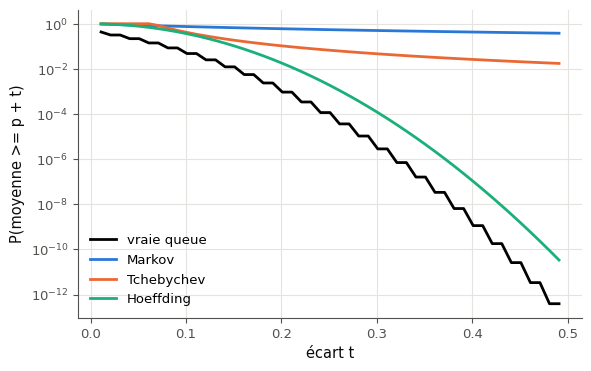

In [34]:
def draw_24(ax, n, p, ts):
    """In ax, against t (the array ts): the true tail P(mean >= p + t) for the mean of n Bernoulli(p), and the bounds
    of Markov, Chebyshev and (one-sided) Hoeffding; log scale for the probabilities, and a legend."""
    ts = np.asarray(ts, dtype=float)
    true_tail = [float(stats.binom.sf(math.ceil(n * (p + t) - 1e-9) - 1, n, p)) for t in ts]
    ax.plot(ts, true_tail, color="black", linewidth=2, label="vraie queue")
    ax.plot(ts, p / (p + ts), label="Markov")
    ax.plot(ts, np.minimum(1.0, p * (1 - p) / (n * ts ** 2)), label="Tchebychev")
    ax.plot(ts, np.exp(-2 * n * ts ** 2), label="Hoeffding")
    ax.set_yscale("log")
    ax.set_ylabel("P(moyenne >= p + t)")
    ax.legend()


fig, ax = plt.subplots(figsize=(6.5, 4))
draw_24(ax, 50, 0.3, np.linspace(0.011, 0.491, 49))
ax.set_xlabel("écart t")
plt.show()

**Vérifications automatiques** (sur d'autres valeurs, dans des axes neufs).

In [35]:
with checked("M11.24 vérifications"):
    problems = []
    n_t, p_t = 80, 0.35
    ts_t = np.linspace(0.021, 0.401, 25)               # n (p + t) is never an integer here
    expected = {
        "la vraie queue P(X̄ >= p + t) (stats.binom)": [float(stats.binom.sf(math.ceil(n_t * (p_t + t) - 1e-9) - 1,
                                                                            n_t, p_t)) for t in ts_t],
        "la borne de Markov p / (p + t)": [min(1.0, p_t / (p_t + t)) for t in ts_t],
        "la borne de Tchebychev p(1 − p) / (n t²), plafonnée à 1": [min(1.0, p_t * (1 - p_t) / (n_t * t ** 2))
                                                                    for t in ts_t],
        "la borne de Hoeffding exp(−2 n t²)": [math.exp(-2 * n_t * t ** 2) for t in ts_t],
    }
    fig_t, ax_t = plt.subplots()
    try:
        created = drawn(draw_24, ax_t, n_t, p_t, ts_t)
    finally:
        plt.close(fig_t)
    if created:
        problems.append("draw_24 ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        curves = [np.asarray(line.get_ydata(), dtype=float) for line in ax_t.get_lines()]
        for what, values in expected.items():
            if not any(len(c) == len(values) and np.allclose(c, values, rtol=1e-6, atol=1e-12) for c in curves):
                problems.append(f"il manque {what}, tracée en fonction de t (une ligne ax.plot sur les ts reçus)")
        if ax_t.get_yscale() != "log":
            problems.append("l'axe des probabilités doit être en échelle log : ax.set_yscale(\"log\")")
        if not ax_t.get_legend():
            problems.append("ajoute une légende (ax.legend()) : quatre courbes sans nom ne se lisent pas")
    if problems:
        print("❌ Ex M11.24 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M11.24 : la vraie queue et les trois bornes sont à leur place, en échelle log, avec une légende.")

✅ Ex M11.24 : la vraie queue et les trois bornes sont à leur place, en échelle log, avec une légende.


💡 Pour $n = 50$ et $p = 0{,}3$ : Hoeffding est la meilleure des trois bornes presque partout ; seuls les très petits écarts ($t < 0{,}033$ environ) laissent Markov devant, et Tchebychev n'est ici jamais la meilleure (elle l'emporte quand la variance est petite, M11.21 b). La vraie queue et la borne de Hoeffding ont toutes deux, en échelle log, la forme d'une parabole en $t$ (un exposant en $t^2$) ; Markov et Tchebychev, des courbes en $\frac{1}{t}$ et $\frac{1}{t^2}$, décroissent trop lentement.

### Ex M11.25 — Chasse à l'erreur : Markov pour une variable négative, Hoeffding sans bornes, un rayon sans racine 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code trois erreurs classiques sur les inégalités de concentration, et calculer ce qu'elles coûtent.  
**Prérequis :** fiche §4 à §6 · **Parcours :** C

Un collègue a écrit le code ci-dessous pour les variations quotidiennes $x_i$ d'un indicateur, dont on sait qu'elles sont toujours comprises entre $-5$ et $5$ (elles peuvent être négatives). Trois lignes ne calculent pas ce que dit leur commentaire. **Sans exécuter de code**, trouve-les.

```python
def report_25(x, threshold, t, delta):
    '''Bounds for n daily changes x, each known to lie in [-5, 5], independent.'''
    n = len(x)
    mean = float(np.mean(x))                                   # (A) the sample mean
    markov = min(1.0, mean / threshold)                        # (B) a bound on P(X >= threshold) for one change X
    variance = float(np.var(x))                                # (C) the sample variance (ddof=0), estimates V(X)
    chebyshev = min(1.0, variance / (n * t ** 2))              # (D) Chebyshev's formula, V(X) replaced by (C)
    hoeffding = min(1.0, 2 * math.exp(-2 * n * t ** 2))        # (E) a bound on P(|mean - mu| >= t)
    radius = 10 * math.log(2 / delta) / (2 * n)                # (F) the Hoeffding radius at risk delta
    return markov, chebyshev, hoeffding, radius
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) la vraie borne de Hoeffding sur $P(\lvert \bar{X} - \mu \rvert \ge 0{,}5)$ pour $n = 400$ variations (4 décimales) ;
- c) le vrai rayon de Hoeffding pour $n = 400$ et $\delta = 0{,}05$ (4 décimales) ;
- d) ce que rend la ligne (F) **telle quelle** pour $n = 400$ et $\delta = 0{,}05$ (4 décimales).

Dans ta copie : corrige les trois lignes. Que vaudrait `markov` pour des variations de moyenne $-0{,}2$, et pourquoi ce nombre n'est-il une borne de rien ? Le rayon faux de d) est-il trop grand ou trop petit, et qu'est-ce que cela fait croire ?

In [36]:
n_25, t_25, delta_25, width_25 = 400, 0.5, 0.05, 10.0          # the changes lie in [-5, 5]: b - a = 10
answer_M11_25a = "BEF"
answer_M11_25b = min(1.0, 2 * math.exp(-2 * n_25 * t_25 ** 2 / width_25 ** 2))   # (E) corrected: (b - a)² = 100
answer_M11_25c = width_25 * math.sqrt(math.log(2 / delta_25) / (2 * n_25))       # (F) corrected: the square root
answer_M11_25d = 10 * math.log(2 / delta_25) / (2 * n_25)                        # (F) as written
print(answer_M11_25a, round(answer_M11_25b, 4), round(answer_M11_25c, 4), round(answer_M11_25d, 4))

BEF 0.2707 0.6791 0.0461


In [37]:
wbm.record("M11.25a", "BEF",
           mistakes={"il manque une ligne fautive : Markov demande une variable positive : les variations quotidiennes peuvent-elles être négatives ?": "EF",
                     "il manque une ligne fautive : les variations sont dans [−5, 5], pas dans [0, 1] : que devient (b − a)² ?": "BF",
                     "il manque une ligne fautive : un rayon de Hoeffding est une racine carrée : regarde ce que calcule la ligne": "BE",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABEF", "BCEF", "BDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : Markov demande une variable positive : les variations quotidiennes peuvent-elles être négatives ?": {"AEF", "CEF", "DEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : les variations sont dans [−5, 5], pas dans [0, 1] : que devient (b − a)² ?": {"ABF", "BCF", "BDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : un rayon de Hoeffding est une racine carrée : regarde ce que calcule la ligne": {"ABE", "BCE", "BDE"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"A", "C", "D", "AB", "AC", "AD", "AE", "AF", "BC", "BD", "CD", "CE", "CF", "DE", "DF", "ABC", "ABD", "ACD", "ACE", "ACF", "ADE", "ADF", "BCD", "CDE", "CDF", "ABCD", "ABCE", "ABCF", "ABDE", "ABDF", "ACDE", "ACDF", "ACEF", "ADEF", "BCDE", "BCDF", "CDEF", "ABCDE", "ABCDF", "ACDEF"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"B", "E", "F"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCEF", "ABDEF", "BCDEF", "ABCDEF"}})
wbm.record("M11.25b", 2 * math.exp(-2.0), decimals=4,
           mistakes={"les variations sont dans [−5, 5] : divise l'exposant par (b − a)² = 100": 2 * math.exp(-200.0)})
wbm.record("M11.25c", 10 * math.sqrt(math.log(40) / 800), decimals=4,
           mistakes={"le rayon est multiplié par b − a = 10": math.sqrt(math.log(40) / 800),
                     "ln(2/δ) = ln 40, à diviser par 2n = 800, puis la racine": 10 * math.sqrt(math.log(20) / 800)})
wbm.record("M11.25d", 10 * math.log(40) / 800, decimals=4,
           mistakes={"la question demande ce que rend la ligne telle quelle, sans racine": 10 * math.sqrt(math.log(40) / 800)})

WBM_ANSWER {"hash": "87cd6ab2ef1f7b9b23ffe7a279ed180678904132e79da1845a0a489f01e4ad5a", "id": "M11.25a", "kind": "str", "mistakes": {"02bb99b03f3dc667996bad890444bccd65bfa50ac3b43514012d96d54e052ae3": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "033113b90298ee082bdc628e7c3205b296509ff779afe87b189e20610b354dca": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "049fe9f25aab50e5707059fbfe83e04d330a995e474da05d8f97b6a2ec015726": "une des lignes que tu cites est correcte, et il manque une ligne fautive : un rayon de Hoeffding est une racine carrée : regarde ce que calcule la ligne", "087eb069276cbb331100bd7e589cf972208bacb742266c24bba7bb4429a5d9cf": "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple", "0a8ecd22e4f8e4f4d17a01afa2f37fc16cc03419414dd902501d1a13556bb281": "une ligne de trop : une des lignes que

💡 (B) Markov suppose $X \ge 0$ : pour des variations de moyenne $-0{,}2$, la ligne rend un nombre négatif, qui n'est la borne d'aucune probabilité. Il faudrait l'appliquer à $X + 5 \ge 0$ : $P(X \ge s) = P(X + 5 \ge s + 5) \le \frac{\mathbb{E}[X] + 5}{s + 5}$. (E) Pour des variables dans $[-5, 5]$, l'exposant est divisé par $(b - a)^2 = 100$ : la ligne fausse donne $2e^{-200}$, une confiance absurde. (F) Sans racine, le rayon vaut 0,046 au lieu de 0,68 : quinze fois trop petit, il fait croire à une précision qu'on n'a pas. (D) est juste à une estimation près : elle remplace $\mathbb{V}(X)$ par la variance de l'échantillon, ce que dit son commentaire.

### Ex M11.26 — Un test paramétré qui vérifie l'inégalité de Markov sur dix lois 🛠️ ★ ⏱️ 15 min
**Objectif :** écrire un test de propriété qui vérifie une borne sur plusieurs lois, et choisir des lois qui attrapent les fausses bornes.  
**Prérequis :** fiche §4 ; Ex M11.17 · **Parcours :** C

Une borne se teste par sa **propriété** : elle doit rester au-dessus de la vraie probabilité, pour toute loi qui vérifie ses hypothèses. Écris `test_markov_bound_on_ten_laws()`, **sans argument** (« paramétré » veut dire ici : une boucle sur une liste de lois **dans** la fonction, pas `@pytest.mark.parametrize`), qui vérifie, pour **dix lois positives** de `scipy.stats` (continues ou discrètes, gelées avec leurs paramètres, comme `stats.expon(scale=2)` ou `stats.bernoulli(0.3)`) et pour plusieurs seuils $a > 0$ chacune, que `markov_bound(law.mean(), a) >= P(X >= a)`, avec une petite tolérance (`1e-12`) et un message d'`assert` qui dit la loi et le seuil.

Attention : pour une loi discrète, `law.sf(a)` vaut $P(X > a)$ ; pour un seuil entier, $P(X \ge a)$ s'écrit `law.sf(a - 1)`, ou bien choisis des seuils non entiers (pour une loi à valeurs entières, $P(X \ge 2{,}5) = P(X > 2{,}5)$).

pytest exécute ta fonction de test **seule**, sans les autres cellules : seuls `math`, `np`, `pytest`, `stats` (`from scipy import stats`) et `markov_bound` lui sont fournis. La vérification la lance trois fois : sur la vraie borne de Markov, où elle doit **passer** ; puis sur `markov_bound_half` et `markov_bound_exp` (fournies), deux fausses bornes, où elle doit **échouer**.

Dans ta copie : quelle loi de ta liste attrape `markov_bound_half` ? Pourquoi une liste de lois « ordinaires » (exponentielle, uniforme, Poisson) peut-elle laisser passer une borne deux fois trop petite ?

In [38]:
markov_bound = wbm.load_mymath("ref").concentration.markov_bound   # the true bound, to run your test here


def markov_bound_half(mean, a):
    """A wrong Markov bound: two times too small."""
    return min(1.0, mean / (2 * a))


def markov_bound_exp(mean, a):
    """A wrong Markov bound: the tail of an exponential law of the same mean, exp(-a / mean)."""
    return math.exp(-a / mean) if mean > 0 else 0.0

In [39]:
def test_markov_bound_on_ten_laws():
    """markov_bound(law.mean(), a) >= P(X >= a) for ten non-negative laws of scipy.stats and several thresholds."""
    laws = {
        "Bernoulli(0.3)": stats.bernoulli(0.3), "Bernoulli(0.9)": stats.bernoulli(0.9),
        "exponential, mean 2": stats.expon(scale=2), "uniform on [0, 4]": stats.uniform(0, 4),
        "Poisson 1.5": stats.poisson(1.5), "binomial (12, 0.4)": stats.binom(12, 0.4),
        "gamma (0.3, 5)": stats.gamma(0.3, scale=5), "lognormal (s = 1.5)": stats.lognorm(1.5),
        "Pareto (b = 1.2)": stats.pareto(1.2), "geometric (0.2)": stats.geom(0.2),
    }
    for name, law in laws.items():
        for a in (0.5, 0.999, 1.5, 3.7, 10.5, 40.5):
            tail = float(law.sf(a))      # thresholds that are not integers: sf(a) = P(X > a) = P(X >= a)
            bound = markov_bound(float(law.mean()), a)
            assert bound >= tail - 1e-12, f"{name}, a = {a}: bound {bound} below P(X >= a) = {tail}"


import inspect

with checked("M11.26 vérifications"):
    if inspect.signature(test_markov_bound_on_ten_laws).parameters:
        raise TypeError("ton test doit s'appeler sans argument : boucle sur tes lois et tes seuils dans la fonction "
                        "(pas de @pytest.mark.parametrize)")
    test_markov_bound_on_ten_laws()                     # your test runs here first: ⏳ while it is not written
    reference_26 = wbm.load_mymath("ref")
    results = {
        "la vraie borne de Markov": (reference_26.concentration.markov_bound, True),
        "une borne deux fois trop petite": (markov_bound_half, False),
        "la queue d'une loi exponentielle prise pour la borne": (markov_bound_exp, False),
    }
    problems = []
    for what, (function, should_pass) in results.items():
        run = wbm.run_pytest(test_markov_bound_on_ten_laws, subject=function, name="markov_bound",
                             preamble="from scipy import stats", quiet=True)
        if "NameError" in run.output:
            problems.append("ton test utilise un nom défini hors de lui (NameError) : pytest l'exécute seul ; seuls "
                            "math, np, pytest, stats et markov_bound lui sont fournis")
            break
        if should_pass and not run.ok:
            problems.append(f"ton test échoue sur {what} : il refuse une fonction juste (lis print(run.output))")
        if not should_pass and run.failed == 0:
            problems.append(f"ton test passe sur {what} : il ne la voit pas ; ajoute une loi où Markov est presque "
                            f"atteinte (une loi à deux valeurs, comme une Bernoulli) ou une loi à queue lourde ; pour une loi "
                            f"discrète à un seuil entier, P(X ≥ a) s'écrit law.sf(a - 1), pas law.sf(a)")
    if problems:
        print("❌ Ex M11.26 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M11.26 : ton test accepte la vraie borne et attrape les deux fausses.")

✅ Ex M11.26 : ton test accepte la vraie borne et attrape les deux fausses.


💡 La loi de Bernoulli(0,9) au seuil 0,999 donne $P(X \ge 0{,}999) = 0{,}9$ et la borne $\frac{0{,}9}{0{,}999} \approx 0{,}901$ : Markov y est presque atteinte (une loi à deux valeurs, 0 et presque le seuil), et la borne deux fois trop petite tombe à 0,45, sous la vraie valeur. Les lois « ordinaires » ont des queues bien plus légères que $\frac{\mathbb{E}[X]}{a}$ : même divisée par 2, une borne fausse reste au-dessus d'elles. La loi de Pareto, à queue lourde, attrape `markov_bound_exp` : sa queue décroît comme une puissance de $a$, plus lentement que l'exponentielle. Un bon test de propriété contient des **cas extrêmes**.

### Ex M11.27 — Défi : la plus petite taille d'échantillon qui garantit une moyenne à ± 0,05 avec 99 %, vérifiée sur une loi défavorable 🏆 ★★★ ⏱️ 25 min
**Objectif :** calculer exactement la taille d'échantillon nécessaire pour une loi défavorable, et la comparer à la garantie de Hoeffding.  
**Prérequis :** fiche §5 et §6 ; Ex M11.22 · **Parcours :** C

Pour des variables à valeurs dans $[0, 1]$, Hoeffding garantit $P(\lvert \bar{X} - \mu \rvert \ge 0{,}05) \le 0{,}01$ dès que $n \ge \frac{\ln 200}{2 \times 0{,}05^2} \approx 1\,059{,}7$, donc pour $n \ge 1\,060$, **quelle que soit** la loi. Est-ce beaucoup trop ? Regardons une loi défavorable : la loi de Bernoulli de paramètre $\frac{1}{2}$, celle dont la variance est la plus grande.

**Le défi.** Écris `smallest_n_27()`, qui rend le plus petit entier $n_0$ tel que, pour **tout** $n$ de $n_0$ à 3 000, la probabilité **exacte** $P\big(\lvert \bar{X} - \frac{1}{2} \rvert \ge 0{,}05\big)$ soit au plus 0,01, où $\bar{X}$ est la moyenne de $n$ variables de Bernoulli$(\frac{1}{2})$ indépendantes. Objectif : la valeur exacte. Deux pièges t'attendent : la probabilité n'est pas une fonction décroissante de $n$ (le nombre de valeurs possibles de $\bar{X}$ change avec $n$), et l'égalité $\lvert \frac{k}{n} - \frac{1}{2} \rvert = 0{,}05$ tombe souvent pile, là où les flottants arrondissent.

Ensuite, dans ta copie : compare ton $n_0$ à la garantie de Hoeffding (1 060) et à l'approximation normale ($n \approx (2{,}576 \times 0{,}5 / 0{,}05)^2 \approx 664$). Pourquoi Hoeffding demande-t-il plus ? Pour ton $n_0$, vérifie que la loi de Bernoulli de paramètre $p$ donne une probabilité plus petite pour $p$ = 0,3 ou 0,1 : pourquoi parle-t-on de loi « défavorable » ?

In [40]:
def smallest_n_27():
    """The smallest n0 such that P(|mean - 1/2| >= 0.05) <= 0.01 for every n from n0 to 3000, for the mean of n
    independent Bernoulli(1/2) (exact binomial probabilities)."""
    probs = {}
    for n in range(1, 3001):
        k = np.arange(n + 1)
        far = 10 * np.abs(2 * k - n) >= n           # |k/n - 1/2| >= 0.05, written with integers only
        probs[n] = float(stats.binom.pmf(k, n, 0.5)[far].sum())
    n0 = 3000
    while n0 > 1 and probs[n0 - 1] <= 0.01:         # go down while the property still holds
        n0 -= 1
    return n0


n_27 = smallest_n_27()
print("n0 =", n_27, "; Hoeffding :", math.ceil(math.log(200) / (2 * 0.05 ** 2)))
for p in (0.5, 0.3, 0.1):
    k = np.arange(n_27 + 1)
    far = np.abs(k - n_27 * p) >= 0.05 * n_27 - 1e-9
    print(f"p = {p} : P(|mean - p| >= 0.05) = {stats.binom.pmf(k, n_27, p)[far].sum():.5f}")

with checked("M11.27"):
    n_27 = smallest_n_27()                   # ⏳ while smallest_n_27 is not written
    wbm.check("M11.27", int(n_27), computed=True)

n0 = 681 ; Hoeffding : 1060
p = 0.5 : P(|mean - p| >= 0.05) = 0.00912
p = 0.3 : P(|mean - p| >= 0.05) = 0.00443
p = 0.1 : P(|mean - p| >= 0.05) = 0.00002


✅ Ex M11.27 : Exact !


In [41]:
wbm.record("M11.27", 681,
           mistakes={"c'est la première taille où la probabilité passe sous 1 % ; elle remonte au-dessus pour des n plus "
                     "grands : vérifie tous les n jusqu'à 3 000": 651,
                     "l'égalité |k/n − 1/2| = 0,05 tombe sur des flottants arrondis : compare des entiers, "
                     "10 |2k − n| >= n": 679,
                     "c'est la garantie de Hoeffding, valable pour toute loi ; le défi demande la valeur exacte pour la "
                     "loi de Bernoulli(1/2)": {1059, 1060},
                     "c'est l'approximation normale ; le défi demande la probabilité exacte": {663, 664}})

WBM_ANSWER {"hash": "55abcab7f6d187ff6f22a205e869c73c2a75aa9f502deee37d36be1083dc9056", "id": "M11.27", "kind": "int", "magnitude": 2, "mistakes": {"3a502766b1037d7ea1ea60c35cf35408da89cc70c23c4024b458d40fa85fdfe1": "l'égalité |k/n − 1/2| = 0,05 tombe sur des flottants arrondis : compare des entiers, 10 |2k − n| >= n", "71c441cba4ad7ac2599653e75f5c9271b0974bc63db9c69c2c6a26a6a3f7de7f": "c'est la garantie de Hoeffding, valable pour toute loi ; le défi demande la valeur exacte pour la loi de Bernoulli(1/2)", "95d3e1e415c7e34ca9722bddec33863adf8e1ab8b43e2100b8a4d2c2dd431421": "c'est l'approximation normale ; le défi demande la probabilité exacte", "ce6b7f4d0a5ded25ea17cd9ebcad4331926965aa40217fb5c981ad16cd539d34": "c'est la garantie de Hoeffding, valable pour toute loi ; le défi demande la valeur exacte pour la loi de Bernoulli(1/2)", "e851c3df71b4f706cb313f6b22c5ae8dda65714cf1cb590eb3ec27316f7fe182": "c'est la première taille où la probabilité passe sous 1 % ; elle remonte au-dessus pour

💡 $n_0 = 681$. La probabilité exacte passe une première fois sous 1 % à $n = 651$, puis remonte au-dessus pour plusieurs $n$ (665, 667, 669, 678 et 680 : ceux où un $k$ tombe pile sur la frontière) ; la comparaison en flottants rate une partie de ces frontières et donne 679. Hoeffding (1 060) demande plus de 1,5 fois plus d'exemples : elle doit valoir pour toutes les lois de $[0, 1]$ et pour tout $n$, avec une marge de sécurité. Pour $p = 0{,}3$ ou $0{,}1$, la variance $p(1 - p)$ est plus petite, et la probabilité d'un écart de 0,05 aussi : Bernoulli($\frac{1}{2}$) est la loi la plus dispersée de $[0, 1]$ parmi celles de moyenne $\frac{1}{2}$, d'où « défavorable ».

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu décider par une table de vérité si un argument est valide, et nier une phrase quantifiée ?
2. Sais-tu traduire une phrase en inclusion d'ensembles, et trouver un contre-exemple ?
3. Sais-tu repérer et chiffrer un piège d'induction (taux de base, échantillon biaisé) ?
4. Sais-tu démontrer Markov et Tchebychev, et en tirer une taille d'échantillon ?
5. Sais-tu calculer un rayon de Hoeffding, et dire ce que l'inégalité suppose ?
6. Sais-tu expliquer d'où vient le bonus d'UCB, et pourquoi ε-greedy à ε fixé a un regret linéaire ?

**La suite** : le chapitre 11 de workbookIA (apprentissage et raisonnement, puis un agent qui apprend par essais et récompenses), puis CP2, l'examen blanc de la partie II.